# HOSE V4 — Nested Walk-Forward FA/TA → Top N → EW / MPT / MinVar / HRP

## Mục tiêu của phiên bản V4

Notebook này được viết lại theo **từng bước nhỏ để dễ trình bày**. Mỗi phần chỉ giải quyết một nhiệm vụ rõ ràng.

**Pipeline nghiên cứu:**

`Dữ liệu → kiểm tra chất lượng → FA (nếu có) / TA → Core Train chọn ngưỡng → Validation chọn mô hình → Nested Walk-Forward tái chọn Top N theo quý → phân bổ EW/MPT/MinVar/HRP theo tháng → Market Regime/Cash → Final Test`

### Nguyên tắc chống future leakage

- Ngưỡng `BUY/EXIT` chỉ được chọn trên **Core Train**.
- Họ mô hình danh mục chỉ được chọn trên **Validation**.
- Trong Validation/Test, Top N được tái chọn tại phiên `t` bằng dữ liệu **chỉ đến t−1**.
- MPT/MinVar/HRP tại phiên `t` chỉ dùng dữ liệu **đến t−1**.
- FA chỉ dùng bản ghi có `effective_date <= ngày ra quyết định`.
- `Close(t−1)` có thể quyết định giao dịch tại `Open(t)`.
- Final Test chỉ để đánh giá; không được nhìn kết quả rồi đổi tham số.

> **Điểm trình bày quan trọng: danh sách Top N không còn khóa cố định cho cả Test. Danh mục được tái chọn theo quý một cách causal, giúp thích nghi với trạng thái thị trường nhưng vẫn không nhìn tương lai.


## PHẦN 0 — Cài đặt thư viện

**Mục đích:** chuẩn bị các thư viện xử lý dữ liệu, tối ưu danh mục và covariance shrinkage.

Nếu Colab đã có sẵn các package này thì cell cài đặt chạy rất nhanh.


In [1]:
!pip -q install pandas numpy matplotlib scipy scikit-learn openpyxl

In [2]:
# ==========================================================
# 0. CÀI THƯ VIỆN + IMPORT
# ==========================================================
import os
import re
import math
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 150)
pd.set_option("display.width", 220)

print("Đã import thư viện thành công.")


Đã import thư viện thành công.


## PHẦN 1 — Cấu hình nghiên cứu

Đây là cell quan trọng nhất khi đổi bộ dữ liệu. Không cần sửa sâu trong các hàm bên dưới.

### Cách V4 thích nghi với dữ liệu khác

- Nếu dữ liệu đủ dài và năm cuối có đủ phiên, V4 ưu tiên dùng **năm cuối làm Final Test**.
- Nếu không, V4 tự chia theo tỷ lệ thời gian.
- V4 yêu cầu tối thiểu khoảng **420 phiên** để còn đủ Core Train + Validation + Test.
- Nếu có FA point-in-time, `FILTER_MODE="auto"` sẽ tự bật FA+TA; nếu không, tự chạy TA-only.


In [3]:
# ==========================================================
# 1. CONFIG - CHỈ CẦN CHỈNH CELL NÀY KHI ĐỔI BỘ DỮ LIỆU
# ==========================================================

# Nếu DATA_PATH = None: Colab sẽ yêu cầu upload file CSV.
DATA_PATH = None
FA_PATH = None
SECTOR_PATH = None

OUTPUT_DIR = Path("./hose_v4_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

USE_ADJUSTED_PRICES = True
BENCHMARK_ALIASES = {"VNINDEX", "VN-INDEX", "VNI", "^VNINDEX", "VNINDEXINDEX"}
TRADING_DAYS = 252
TOP_N = 5

# ----- Chia dữ liệu theo thời gian -----
SPLIT_MODE = "auto"          # "auto" hoặc "proportions"
TRAIN_PROP = 0.60
VALIDATION_PROP = 0.20
TEST_PROP = 0.20
MIN_TOTAL_SESSIONS = 420
MIN_CORE_TRAIN_SESSIONS = 252
MIN_VALIDATION_SESSIONS = 63
MIN_TEST_SESSIONS = 100
PREFER_LAST_FULL_YEAR_TEST = True
LAST_YEAR_MIN_SESSIONS = 180

# ----- Bộ lọc TA Group 1 -----
BUY_CHOICES = [5, 6, 7]
EXIT_CHOICES = [2, 3, 4]
MIN_TA_SCORE_AT_SELECTION = 4
N_THRESHOLD_FOLDS = 3
GLOBAL_THRESHOLD_STABILITY_PENALTY = 0.20

# ----- Universe / thanh khoản -----
USE_LIQUIDITY_FILTER = True
LIQUIDITY_LOOKBACK = 60
LIQUIDITY_MIN_PERCENTILE = 0.20
MIN_HISTORY_FLOOR = 180
MIN_HISTORY_CAP = 400

# ----- Xếp hạng cổ phiếu -----
RANK_W_TRAILING = 0.25
RANK_W_TA = 0.20
RANK_W_REL_STRENGTH = 0.25
RANK_W_LOW_VOL = 0.10
RANK_W_LIQUIDITY = 0.05
RANK_W_MOMENTUM = 0.15

SELECTION_TRAILING_LOOKBACK = 126
MAX_VOL_PERCENTILE = 0.75
MIN_TRAILING_DD_PERCENTILE = 0.15
MAX_SELECTION_RSI = 80.0
MAX_PAIRWISE_CORR = 0.80
CORR_LOOKBACK = 126

# ----- Nested Walk-Forward -----
STOCK_SELECTION_FREQUENCY = "Q"       # tái chọn Top N theo quý
ALLOCATION_REBALANCE_FREQUENCY = "M"  # cập nhật trọng số theo tháng

# ----- Fundamental Analysis tùy chọn -----
FILTER_MODE = "auto"        # "auto" | "TA" | "FA_TA"
ALLOW_UNDATED_FA = False
MIN_FA_METRICS_PER_STOCK = 2
MIN_FA_COVERAGE_RATIO = 0.50
FA_WEIGHT = 0.30
TA_WEIGHT = 0.70
MAX_STOCKS_PER_SECTOR = 2

# ----- Portfolio -----
INITIAL_CASH = 1_000_000_000.0
PORTFOLIO_COMMISSION = 0.0015
SLIPPAGE = 0.0005
ALLOW_FRACTIONAL_SHARES = False
RISK_FREE_RATE = 0.0
WEIGHT_LOOKBACK = 252
MPT_MAX_WEIGHT = 0.50
MPT_L2_GAMMA = 0.03
MU_SHRINKAGE = 0.50
BLEND_MPT_WEIGHT = 0.50

# ----- Risk overlay -----
USE_MARKET_REGIME = True
MARKET_EMA_SPAN = 200
MARKET_EMA_SLOPE_LOOKBACK = 20
USE_EMA_SLOPE_CONFIRMATION = True
USE_STOCK_ACTIVE_MASK = True

# Stop loss để sẵn nhưng OFF mặc định để tránh overfit.
ENABLE_INDIVIDUAL_TRAILING_STOP = False
INDIVIDUAL_TRAILING_STOP_PCT = 0.12
ENABLE_PORTFOLIO_TRAILING_STOP = False
PORTFOLIO_TRAILING_STOP_PCT = 0.15

print("TOP_N =", TOP_N)
print("Stock selection =", STOCK_SELECTION_FREQUENCY, "| Allocation rebalance =", ALLOCATION_REBALANCE_FREQUENCY)


TOP_N = 5
Stock selection = Q | Allocation rebalance = M


## PHẦN 2 — Đọc và chuẩn hóa OHLCV

**Mục đích:** đưa mọi file giá về cùng cấu trúc `Ticker, Date, Open, High, Low, Close, Volume`.

V4 ưu tiên `adj_open/adj_high/adj_low/adj_close` nếu bộ dữ liệu có đủ các cột adjusted.

**Chống leakage:** bước này chỉ làm sạch dữ liệu, chưa dùng bất kỳ thông tin tương lai nào để chọn cổ phiếu.


In [4]:
# 2A. Hàm đọc và chuẩn hóa dữ liệu

def _canon(s):
    return re.sub(r"[^a-z0-9]", "", str(s).strip().lower())

def find_col(df, candidates):
    lookup = {_canon(c): c for c in df.columns}
    for c in candidates:
        if _canon(c) in lookup:
            return lookup[_canon(c)]
    return None

def load_csv(path=None, prompt="Upload CSV"):
    """Đọc file từ path; nếu chạy Colab và path=None thì bật hộp upload."""
    if path is not None and os.path.exists(path):
        print("Đọc file:", path)
        return pd.read_csv(path)
    try:
        from google.colab import files
        print(prompt)
        uploaded = files.upload()
        if not uploaded:
            raise ValueError("Không có file được upload")
        fname = next(iter(uploaded))
        print("Đọc file upload:", fname)
        return pd.read_csv(fname)
    except Exception as e:
        raise ValueError("Hãy đặt DATA_PATH hợp lệ hoặc upload CSV trong Colab") from e

def parse_dates_safely(s):
    """Ưu tiên mm/dd/yyyy vì bộ HOSE hiện tại dùng định dạng này; có fallback tự động."""
    s = pd.Series(s)
    x = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")
    if x.notna().mean() < 0.80:
        x = pd.to_datetime(s, errors="coerce", dayfirst=False)
    if x.notna().mean() < 0.80:
        x = pd.to_datetime(s, errors="coerce", dayfirst=True)
    return x

def standardize_ohlcv(df_raw, use_adjusted=True):
    """Chuẩn hóa mọi bộ dữ liệu về Ticker-Date-OHLCV; ưu tiên adjusted OHLC nếu có đủ."""
    df = df_raw.copy()
    df.columns = [str(c).strip() for c in df.columns]
    ticker_col = find_col(df, ["ticker", "symbol", "code", "stock_code", "mack"])
    date_col = find_col(df, ["date", "datetime", "trading_date", "time", "ngay"])
    volume_col = find_col(df, ["volume", "vol", "trading_volume", "khoiluong"])

    raw_cols = {
        "Open": find_col(df, ["open", "open_price"]),
        "High": find_col(df, ["high", "high_price"]),
        "Low": find_col(df, ["low", "low_price"]),
        "Close": find_col(df, ["close", "close_price"]),
    }
    adj_cols = {
        "Open": find_col(df, ["adj_open", "adjusted_open"]),
        "High": find_col(df, ["adj_high", "adjusted_high"]),
        "Low": find_col(df, ["adj_low", "adjusted_low"]),
        "Close": find_col(df, ["adj_close", "adjusted_close", "adjclose"]),
    }
    if ticker_col is None or date_col is None:
        raise ValueError(f"Thiếu cột ticker/date. Các cột hiện có: {list(df.columns)}")

    use_adj = bool(use_adjusted and all(v is not None for v in adj_cols.values()))
    pcols = adj_cols if use_adj else raw_cols
    if not all(v is not None for v in pcols.values()):
        raise ValueError("Thiếu đầy đủ các cột OHLC")

    out = pd.DataFrame({
        "Ticker": df[ticker_col].astype(str).str.strip().str.upper(),
        "Date": parse_dates_safely(df[date_col]),
        "Open": pd.to_numeric(df[pcols["Open"]], errors="coerce"),
        "High": pd.to_numeric(df[pcols["High"]], errors="coerce"),
        "Low": pd.to_numeric(df[pcols["Low"]], errors="coerce"),
        "Close": pd.to_numeric(df[pcols["Close"]], errors="coerce"),
        "Volume": pd.to_numeric(df[volume_col], errors="coerce") if volume_col else 0.0,
    })
    out = out.dropna(subset=["Ticker", "Date", "Open", "High", "Low", "Close"])
    out = out[(out[["Open", "High", "Low", "Close"]] > 0).all(axis=1)]
    out["Volume"] = out["Volume"].fillna(0).clip(lower=0)

    valid_ohlc = (
        (out["High"] >= out[["Open", "Close", "Low"]].max(axis=1)) &
        (out["Low"] <= out[["Open", "Close", "High"]].min(axis=1))
    )
    out = out.loc[valid_ohlc]
    out = out.drop_duplicates(["Ticker", "Date"], keep="last")
    out = out.sort_values(["Ticker", "Date"]).reset_index(drop=True)

    print(f"Nguồn giá: {'ADJUSTED' if use_adj else 'RAW'}")
    print(f"Số dòng: {len(out):,} | Số mã: {out['Ticker'].nunique()}")
    print("Khoảng thời gian:", out["Date"].min().date(), "->", out["Date"].max().date())
    return out

In [5]:
# 2B. Hàm kiểm tra chất lượng dữ liệu

def data_quality_table(data):
    """Bảng kiểm tra nhanh độ phủ dữ liệu từng mã."""
    rows = []
    for t, g in data.groupby("Ticker"):
        rows.append({
            "Ticker": t,
            "Start": g["Date"].min(),
            "End": g["Date"].max(),
            "Sessions": g["Date"].nunique(),
            "MissingVolumePct": 100 * g["Volume"].isna().mean(),
            "MedianTradedValue": (g["Close"] * g["Volume"]).median(),
        })
    return pd.DataFrame(rows).sort_values("Sessions", ascending=False).reset_index(drop=True)

In [6]:
# 2C. Đọc dữ liệu thực tế
import os

def load_data_flexibly(path=None, prompt="Hãy upload file dữ liệu (CSV hoặc Excel)"):
    """Đọc file từ path hoặc hỗ trợ upload trong Colab, tự động nhận diện CSV hay Excel."""
    fname = None
    if path is not None and os.path.exists(path):
        print("Đọc file từ đường dẫn:", path)
        fname = path
    else:
        try:
            from google.colab import files
            print(prompt)
            uploaded = files.upload()
            if not uploaded:
                raise ValueError("Không có file nào được tải lên.")
            fname = next(iter(uploaded))
            print("Đọc file upload:", fname)
        except Exception as e:
            raise ValueError("Hãy đặt DATA_PATH hợp lệ hoặc upload file trong Colab.") from e

    if fname.endswith(('.xlsx', '.xls')):
        return pd.read_excel(fname)
    else:
        return pd.read_csv(fname)

# Đọc dữ liệu thực tế
raw = load_data_flexibly(DATA_PATH, prompt="Hãy upload file dữ liệu OHLCV (CSV hoặc Excel)")

# Khắc phục lỗi lệch tên cột tiếng Việt có dấu bằng cách ánh xạ nhanh
rename_dict = {
    "Mã": "Ticker",
    "Ngày": "Date",
    "Giá mở cửa": "Open",
    "Giá cao nhất": "High",
    "Giá thấp nhất": "Low",
    "Giá đóng cửa": "Close",
    "Giá điều chỉnh": "adj_close",
    "Khối lượng khớp lệnh": "Volume"
}
raw = raw.rename(columns=rename_dict)

# Xử lý và chuẩn hóa dữ liệu
data = standardize_ohlcv(raw, USE_ADJUSTED_PRICES)
quality = data_quality_table(data)

display(quality.head(10))
print("\nSố phiên toàn thị trường:", data["Date"].nunique())
print("Số mã:", data["Ticker"].nunique())
print("Từ:", data["Date"].min().date(), "đến:", data["Date"].max().date())

Hãy upload file dữ liệu OHLCV (CSV hoặc Excel)


Saving HOSE - 01.01.2021 - 31.12.2025 (98 mã bao gồm VNINDEX).xlsx to HOSE - 01.01.2021 - 31.12.2025 (98 mã bao gồm VNINDEX) (1).xlsx
Đọc file upload: HOSE - 01.01.2021 - 31.12.2025 (98 mã bao gồm VNINDEX) (1).xlsx
Nguồn giá: RAW
Số dòng: 120,290 | Số mã: 98
Khoảng thời gian: 2021-01-04 -> 2025-12-31


,Ticker,Start,End,Sessions,MissingVolumePct,MedianTradedValue
0,VNINDEX,2021-01-04,2025-12-31,1242,0.0,8.673878e+11
1,KDH,2021-01-04,2025-12-31,1241,0.0,6.921038e+07
2,PET,2021-01-04,2025-12-31,1240,0.0,2.589156e+07
3,PLX,2021-01-04,2025-12-31,1240,0.0,5.077829e+07
4,PVD,2021-01-04,2025-12-31,1240,0.0,1.299739e+08
5,LPB,2021-01-04,2025-12-31,1240,0.0,1.077348e+08
6,KSB,2021-01-04,2025-12-31,1240,0.0,4.270616e+07
7,LCG,2021-01-04,2025-12-31,1240,0.0,4.710364e+07
8,OGC,2021-01-04,2025-12-31,1240,0.0,4.065585e+06
9,NLG,2021-01-04,2025-12-31,1240,0.0,8.663246e+07



Số phiên toàn thị trường: 1246
Số mã: 98
Từ: 2021-01-04 đến: 2025-12-31


## PHẦN 3 — Fundamental Analysis tùy chọn và Sector Map

### Logic FA

V4 chỉ sử dụng FA khi có **ngày thông tin có hiệu lực/công bố**. Ví dụ BCTC quý IV kết thúc 31/12 nhưng công bố tháng 2 thì không được coi là biết từ 31/12.

Nếu không tìm thấy FA point-in-time an toàn, code tự chuyển sang **TA-only**.

### Logic ngành

Nếu có `Ticker → Sector`, code giới hạn số mã cùng ngành. Nếu không có sector, V4 vẫn dùng **correlation cap** để giảm tập trung rủi ro.


In [7]:
FA_ALIASES = {
    "ROE": ["roe", "return_on_equity", "returnonequity"],
    "ROA": ["roa", "return_on_assets", "returnonassets"],
    "RevenueGrowth": ["revenue_growth", "sales_growth", "revenuegrowth", "tangtruongdoanhthu"],
    "EPSGrowth": ["eps_growth", "epsgrowth", "tangtruongeps"],
    "GrossMargin": ["gross_margin", "grossmargin", "bienloinhuangop"],
    "OperatingMargin": ["operating_margin", "operatingmargin"],
    "NetMargin": ["net_margin", "netmargin", "bienloinhuanrong"],
    "CurrentRatio": ["current_ratio", "currentratio"],
    "DebtToEquity": ["debt_to_equity", "de", "d_e", "debttoequity"],
    "PE": ["pe", "p_e", "price_to_earnings", "pricetoearnings"],
    "PB": ["pb", "p_b", "price_to_book", "pricetobook"],
    "EVEBITDA": ["ev_ebitda", "evebitda"],
}


# 3A. Chuẩn hóa FA và ngành

def standardize_fa(df):
    """FA phải có ngày effective/publish để đảm bảo point-in-time."""
    if df is None or len(df) == 0:
        return None
    d = df.copy()
    d.columns = [str(c).strip() for c in d.columns]
    ticker_col = find_col(d, ["ticker", "symbol", "code", "stock_code", "mack"])
    date_col = find_col(d, ["effective_date", "publish_date", "announcement_date", "report_date", "date", "ngay"])
    if ticker_col is None:
        return None

    out = pd.DataFrame({"Ticker": d[ticker_col].astype(str).str.strip().str.upper()})
    if date_col is not None:
        out["Date"] = parse_dates_safely(d[date_col])
    elif ALLOW_UNDATED_FA:
        out["Date"] = pd.Timestamp("1900-01-01")
    else:
        return None

    found = 0
    for canon_name, aliases in FA_ALIASES.items():
        c = find_col(d, aliases)
        if c is not None:
            out[canon_name] = pd.to_numeric(d[c], errors="coerce")
            found += 1
    if found == 0:
        return None
    return out.dropna(subset=["Ticker", "Date"]).sort_values(["Ticker", "Date"])

def load_optional_fa(df_raw, fa_path=None):
    if fa_path is not None and os.path.exists(fa_path):
        fa = standardize_fa(pd.read_csv(fa_path))
        if fa is not None:
            print("FA: bật từ file riêng | Chỉ tiêu:", [c for c in fa.columns if c not in ["Ticker", "Date"]])
            return fa
    fa = standardize_fa(df_raw)
    if fa is not None:
        print("FA: phát hiện trực tiếp trong file thị trường | Chỉ tiêu:", [c for c in fa.columns if c not in ["Ticker", "Date"]])
        return fa
    print("FA: không có dữ liệu point-in-time an toàn -> tự động chuyển sang TA-only")
    return None

def load_sector_map(df_raw, sector_path=None):
    src = pd.read_csv(sector_path) if sector_path is not None and os.path.exists(sector_path) else df_raw.copy()
    ticker_col = find_col(src, ["ticker", "symbol", "code", "stock_code", "mack"])
    sector_col = find_col(src, ["sector", "industry", "industry_group", "nganh"])
    if ticker_col is None or sector_col is None:
        print("Sector: không có -> dùng correlation cap làm lớp đa dạng hóa thay thế")
        return {}
    m = src[[ticker_col, sector_col]].dropna().drop_duplicates(ticker_col, keep="last")
    m[ticker_col] = m[ticker_col].astype(str).str.upper().str.strip()
    mapping = dict(zip(m[ticker_col], m[sector_col].astype(str)))
    print("Sector: đã tải", len(mapping), "mã")
    return mapping

In [8]:
# 3B. FA snapshot point-in-time

def fa_snapshot_score(fa, asof_date, tickers):
    """Chỉ lấy bản FA gần nhất có Date <= asof_date."""
    if fa is None or fa.empty:
        return pd.DataFrame(index=tickers)
    x = fa[(fa["Date"] <= pd.Timestamp(asof_date)) & (fa["Ticker"].isin(tickers))].copy()
    if x.empty:
        return pd.DataFrame(index=tickers)
    x = x.sort_values("Date").groupby("Ticker", as_index=False).tail(1).set_index("Ticker")
    metrics = [c for c in FA_ALIASES if c in x.columns]
    if not metrics:
        return pd.DataFrame(index=tickers)

    lower_better = {"DebtToEquity", "PE", "PB", "EVEBITDA"}
    score_parts = []
    for c in metrics:
        s = pd.to_numeric(x[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
        if c in {"PE", "PB", "EVEBITDA"}:
            s = s.where(s > 0)
        lo, hi = s.quantile(0.05), s.quantile(0.95)
        if pd.notna(lo) and pd.notna(hi) and hi > lo:
            s = s.clip(lo, hi)
        pct = s.rank(pct=True)
        if c in lower_better:
            pct = 1 - pct + (1 / max(len(pct.dropna()), 1))
        score_parts.append(pct.rename(c))

    z = pd.concat(score_parts, axis=1)
    out = pd.DataFrame(index=x.index)
    out["FA_MetricCount"] = z.notna().sum(axis=1)
    out["FA_Score"] = z.mean(axis=1) * 100
    return out.reindex(tickers)

In [9]:
# 3C. Tự động kiểm tra FA / Sector
fa = load_optional_fa(raw, FA_PATH)
sector_map = load_sector_map(raw, SECTOR_PATH)

print("\nChế độ dữ liệu:")
print("- FA:", "Có" if fa is not None else "Không")
print("- Sector map:", "Có" if len(sector_map) else "Không")


FA: không có dữ liệu point-in-time an toàn -> tự động chuyển sang TA-only
Sector: không có -> dùng correlation cap làm lớp đa dạng hóa thay thế

Chế độ dữ liệu:
- FA: Không
- Sector map: Không


## PHẦN 4 — Chia Core Train / Validation / Final Test

**Vai trò của từng tập:**

- **Core Train:** chọn ngưỡng TA chung.
- **Validation:** chạy nested walk-forward và chọn họ mô hình tốt nhất.
- **Final Test:** chỉ đánh giá mô hình đã khóa.

Việc chia hoàn toàn theo **thứ tự thời gian**, không shuffle.


In [10]:
# 4A. Hàm chia dữ liệu

def resolve_auto_splits(data):
    dates = pd.DatetimeIndex(sorted(pd.to_datetime(data["Date"].unique())))
    n = len(dates)
    if n < MIN_TOTAL_SESSIONS:
        raise ValueError(
            f"Bộ dữ liệu chỉ có {n} phiên. V4 cần tối thiểu khoảng {MIN_TOTAL_SESSIONS} phiên "
            "để có Core Train + Validation + Final Test riêng biệt."
        )

    if SPLIT_MODE == "proportions":
        i_train = max(MIN_CORE_TRAIN_SESSIONS, int(n * TRAIN_PROP))
        i_val_end = max(i_train + MIN_VALIDATION_SESSIONS, int(n * (TRAIN_PROP + VALIDATION_PROP)))
        i_val_end = min(i_val_end, n - MIN_TEST_SESSIONS)
        if i_val_end <= i_train:
            raise ValueError("Không đủ dữ liệu để chia Validation/Test")
        core_end = dates[i_train - 1]
        val_start, val_end = dates[i_train], dates[i_val_end - 1]
        test_start, test_end = dates[i_val_end], dates[-1]
        return dates, core_end, val_start, val_end, test_start, test_end

    # AUTO: ưu tiên dùng năm cuối đủ dài làm Final Test.
    last_year = dates[-1].year
    last_year_dates = dates[dates.year == last_year]
    pre_last_year_count = int((dates < last_year_dates[0]).sum()) if len(last_year_dates) else 0
    if (
        PREFER_LAST_FULL_YEAR_TEST and
        len(last_year_dates) >= LAST_YEAR_MIN_SESSIONS and
        pre_last_year_count >= MIN_CORE_TRAIN_SESSIONS + MIN_VALIDATION_SESSIONS
    ):
        test_start, test_end = last_year_dates[0], last_year_dates[-1]
        pretest = dates[dates < test_start]
    else:
        test_n = max(MIN_TEST_SESSIONS, min(252, int(round(TEST_PROP * n))))
        test_start, test_end = dates[-test_n], dates[-1]
        pretest = dates[dates < test_start]

    # Validation: tối đa khoảng nửa năm nếu lịch sử ngắn; có thể dài hơn ở dữ liệu lớn.
    val_n = max(MIN_VALIDATION_SESSIONS, min(252, int(round(0.25 * len(pretest)))))
    val_n = min(val_n, len(pretest) - MIN_CORE_TRAIN_SESSIONS)
    if val_n < MIN_VALIDATION_SESSIONS:
        raise ValueError("Không đủ lịch sử trước Test để tách Validation riêng")

    val_start, val_end = pretest[-val_n], pretest[-1]
    core_end = pretest[-val_n - 1]
    return dates, core_end, val_start, val_end, test_start, test_end

In [11]:
# 4B. Thực hiện chia tập
dates, core_end, val_start, val_end, test_start, test_end = resolve_auto_splits(data)

split_table = pd.DataFrame([
    {"Set":"Core Train", "Start":dates[0], "End":core_end, "Sessions":int((dates<=core_end).sum())},
    {"Set":"Validation", "Start":val_start, "End":val_end, "Sessions":int(((dates>=val_start)&(dates<=val_end)).sum())},
    {"Set":"Final Test", "Start":test_start, "End":test_end, "Sessions":int((dates>=test_start).sum())},
])

display(split_table)


,Set,Start,End,Sessions
0,Core Train,2021-01-04,2023-12-29,748
1,Validation,2024-01-02,2024-12-31,250
2,Final Test,2025-01-02,2025-12-31,248


## PHẦN 5 — Chuyển dữ liệu thành từng mã và xác định Benchmark

Nếu có `VNINDEX`, V4 sử dụng VN-Index. Nếu không có, code tạo một **equal-weight market proxy** làm phương án dự phòng.


In [12]:
# 5A. Price dictionary và market proxy

def build_price_dict(data):
    return {
        t: g[["Date", "Open", "High", "Low", "Close", "Volume"]]
             .drop_duplicates("Date").sort_values("Date").set_index("Date")
        for t, g in data.groupby("Ticker")
    }

def build_synthetic_market_proxy(price_dict, exclude=None):
    """Nếu không có VNINDEX, tạo proxy equal-weight từ các cổ phiếu (chỉ để benchmark/regime dự phòng)."""
    exclude = set(exclude or [])
    closes = [px["Close"].rename(t) for t, px in price_dict.items() if t not in exclude]
    m = pd.concat(closes, axis=1).sort_index()
    ret = m.pct_change(fill_method=None)
    ewret = ret.mean(axis=1, skipna=True).fillna(0)
    close = 1000 * (1 + ewret).cumprod()
    return pd.DataFrame({"Open": close, "High": close, "Low": close, "Close": close, "Volume": 0.0}, index=close.index)

In [13]:
# 5B. Xác định benchmark
price_dict = build_price_dict(data)

benchmark_ticker = next((t for t in price_dict if t in BENCHMARK_ALIASES), None)
if benchmark_ticker is None:
    benchmark_ticker = "__MARKET_PROXY__"
    price_dict[benchmark_ticker] = build_synthetic_market_proxy(price_dict)
    print("Không tìm thấy VNINDEX -> dùng market proxy.")
else:
    print("Benchmark:", benchmark_ticker)


Benchmark: VNINDEX


## PHẦN 6 — Tính chỉ báo kỹ thuật và TA Score 0–10

Phần này giữ tinh thần bộ lọc của **Nhóm 1**:

- Trend Score
- Momentum Score
- Volume Score
- Volatility Score

V4 bổ sung thêm các biến phục vụ ranking: Momentum 63/126/252 ngày, Volatility 63 ngày và Drawdown 126 ngày.

**Warm-up hợp lệ:** EMA200/SMA dài hạn được phép dùng dữ liệu Train trước đó để tính chỉ báo ở Test. Đây không phải future leakage vì chỉ dùng quá khứ.


In [14]:
# 6A. Các hàm indicator cơ bản

def ema(s, span):
    return s.ewm(span=span, adjust=False, min_periods=span).mean()

def rsi_wilder(close, window=14):
    d = close.diff()
    gain, loss = d.clip(lower=0), -d.clip(upper=0)
    ag = gain.ewm(alpha=1/window, adjust=False, min_periods=window).mean()
    al = loss.ewm(alpha=1/window, adjust=False, min_periods=window).mean()
    rs = ag / al.replace(0, np.nan)
    rsi = 100 - 100/(1+rs)
    rsi.loc[(al == 0) & (ag > 0)] = 100
    rsi.loc[(ag == 0) & (al > 0)] = 0
    return rsi

def atr_wilder(df, window=14):
    prev = df["Close"].shift(1)
    tr = pd.concat([
        df["High"] - df["Low"],
        (df["High"] - prev).abs(),
        (df["Low"] - prev).abs()
    ], axis=1).max(axis=1)
    return tr.ewm(alpha=1/window, adjust=False, min_periods=window).mean()

def adx_wilder(df, window=14):
    high, low = df["High"], df["Low"]
    up, down = high.diff(), -low.diff()
    plus_dm = pd.Series(np.where((up > down) & (up > 0), up, 0.0), index=df.index)
    minus_dm = pd.Series(np.where((down > up) & (down > 0), down, 0.0), index=df.index)
    atr = atr_wilder(df, window)
    plus_di = 100 * plus_dm.ewm(alpha=1/window, adjust=False, min_periods=window).mean() / atr.replace(0, np.nan)
    minus_di = 100 * minus_dm.ewm(alpha=1/window, adjust=False, min_periods=window).mean() / atr.replace(0, np.nan)
    dx = 100 * (plus_di-minus_di).abs() / (plus_di+minus_di).replace(0, np.nan)
    adx = dx.ewm(alpha=1/window, adjust=False, min_periods=window).mean()
    return adx, plus_di, minus_di

In [15]:
# 6B. Feature engineering + TA Score

def calculate_ta_features(df):
    out = df.copy().sort_index()
    out["EMA20"] = ema(out["Close"], 20)
    out["EMA50"] = ema(out["Close"], 50)
    out["EMA200"] = ema(out["Close"], 200)

    ema12, ema26 = ema(out["Close"], 12), ema(out["Close"], 26)
    out["MACD"] = ema12 - ema26
    out["MACD_Signal"] = ema(out["MACD"], 9)

    out["ADX"], out["Plus_DI"], out["Minus_DI"] = adx_wilder(out, 14)
    out["ATR"] = atr_wilder(out, 14)
    out["ATR_pct"] = 100 * out["ATR"] / out["Close"].replace(0, np.nan)
    out["ATR_pct_Q90"] = out["ATR_pct"].rolling(126, min_periods=40).quantile(0.90)

    out["Volume_MA20"] = out["Volume"].rolling(20, min_periods=20).mean()
    out["Volume_Ratio"] = out["Volume"] / out["Volume_MA20"].replace(0, np.nan)
    out["OBV"] = (np.sign(out["Close"].diff()).fillna(0) * out["Volume"]).cumsum()
    out["OBV_EMA20"] = ema(out["OBV"], 20)

    out["RSI"] = rsi_wilder(out["Close"], 14)
    out["ROC10"] = out["Close"].pct_change(10) * 100
    out["High_52W"] = out["High"].rolling(252, min_periods=150).max()
    out["Close_to_52W_High"] = out["Close"] / out["High_52W"].replace(0, np.nan)
    out["Avg_Traded_Value_60"] = (out["Close"] * out["Volume"]).rolling(60, min_periods=20).mean()

    out["Momentum63"] = out["Close"].pct_change(63)
    out["Momentum126"] = out["Close"].pct_change(126)
    out["Momentum252"] = out["Close"].pct_change(252)
    out["Vol63"] = out["Close"].pct_change().rolling(63, min_periods=40).std() * np.sqrt(TRADING_DAYS)
    rollmax = out["Close"].rolling(126, min_periods=60).max()
    out["DD126"] = out["Close"] / rollmax - 1

    # TA Score 0-10 theo cấu trúc Group 1
    out["Trend_Score"] = (
        (out["Close"] > out["EMA50"]).astype(int)*2 +
        (out["EMA50"] > out["EMA200"]).astype(int)*2 +
        (out["MACD"] > out["MACD_Signal"]).astype(int)
    ).clip(0, 5)
    momentum_core = ((out["RSI"] >= 45) & (out["RSI"] <= 75)) | (out["ROC10"] > 0)
    out["Momentum_Score"] = (
        momentum_core.astype(int)*2 +
        (out["Close_to_52W_High"] >= 0.85).astype(int)
    ).clip(0, 3)
    out["Volume_Score"] = ((out["Volume_Ratio"] >= 1.0) | (out["OBV"] > out["OBV_EMA20"])).astype(int)
    out["Volatility_Score"] = (
        out["ATR_pct"].notna() & out["ATR_pct_Q90"].notna() &
        (out["ATR_pct"] <= out["ATR_pct_Q90"])
    ).astype(int)
    out["TA_Score"] = (
        out["Trend_Score"] + out["Momentum_Score"] +
        out["Volume_Score"] + out["Volatility_Score"]
    ).clip(0, 10).astype(int)
    return out

def stateful_active_from_score(score, buy_threshold, exit_threshold):
    state = 0
    vals = []
    for v in score.fillna(-np.inf):
        if v >= buy_threshold:
            state = 1
        elif v <= exit_threshold:
            state = 0
        vals.append(state)
    return pd.Series(vals, index=score.index, dtype=int)

In [16]:
# 6C. Tính features cho toàn bộ mã
feature_store = {t: calculate_ta_features(px) for t, px in price_dict.items()}

sample_ticker = next(t for t in feature_store if t != benchmark_ticker)
print("Ví dụ mã:", sample_ticker)
display(feature_store[sample_ticker][[
    "Close","EMA20","EMA50","EMA200","RSI","Momentum126","Vol63","TA_Score"
]].tail())


Ví dụ mã: AAA


,Close,EMA20,EMA50,EMA200,RSI,Momentum126,Vol63,TA_Score
Date,,,,,,,,
2025-12-25,7.91,8.155669,8.168287,8.179615,40.576851,0.091034,0.331899,2
2025-12-26,7.80,8.121796,8.153845,8.175838,37.625854,0.090909,0.329685,1
2025-12-29,7.83,8.094006,8.141145,8.172397,38.930310,0.082988,0.326630,2
2025-12-30,7.85,8.070767,8.129728,8.169189,39.833692,0.090278,0.322966,2
2025-12-31,7.88,8.052599,8.119934,8.166311,41.237861,0.092926,0.323050,2


## PHẦN 7 — Chọn ngưỡng BUY/EXIT chung trên Core Train

Thay vì tối ưu một bộ tham số riêng cho từng cổ phiếu, V4 chọn **một cặp BUY/EXIT chung cho toàn universe**.

Điều này giảm nguy cơ overfit và làm mô hình dễ giải thích hơn.

Tín hiệu ở `Close(t)` luôn được dịch sang giao dịch ở `Open(t+1)`.


In [17]:
# 7A. Metrics + backtest một cổ phiếu

def annualized_sharpe(r):
    r = pd.Series(r).replace([np.inf, -np.inf], np.nan).dropna()
    return np.sqrt(TRADING_DAYS)*r.mean()/r.std(ddof=1) if len(r) > 1 and r.std(ddof=1) > 1e-12 else np.nan

def annualized_sortino(r):
    r = pd.Series(r).replace([np.inf, -np.inf], np.nan).dropna()
    neg = r[r < 0]
    return np.sqrt(TRADING_DAYS)*r.mean()/neg.std(ddof=1) if len(neg) > 1 and neg.std(ddof=1) > 1e-12 else np.nan

def metrics_from_equity(eq):
    eq = pd.Series(eq).dropna()
    if len(eq) < 2:
        return {}
    r = eq.pct_change().dropna()
    total = eq.iloc[-1]/eq.iloc[0]-1
    years = max((eq.index[-1]-eq.index[0]).days/365.25, 1/365.25)
    cagr = (eq.iloc[-1]/eq.iloc[0])**(1/years)-1
    dd = eq/eq.cummax()-1
    mdd = dd.min()
    vol = r.std(ddof=1)*np.sqrt(TRADING_DAYS) if len(r) > 1 else np.nan
    return {
        "Return [%]": total*100,
        "CAGR [%]": cagr*100,
        "Sharpe": annualized_sharpe(r),
        "Sortino": annualized_sortino(r),
        "Volatility [%]": vol*100 if pd.notna(vol) else np.nan,
        "MaxDD [%]": mdd*100 if pd.notna(mdd) else np.nan,
        "Calmar": cagr/abs(mdd) if pd.notna(mdd) and mdd < 0 else np.nan,
    }

def simulate_single_stock(features, start, end, buy_threshold, exit_threshold, initial_cash=1_000_000.0):
    """Backtest 1 cổ phiếu: tín hiệu Close(t) chỉ được giao dịch ở Open(t+1)."""
    active_close = stateful_active_from_score(features["TA_Score"], buy_threshold, exit_threshold)
    active_open = active_close.shift(1).fillna(0).astype(int)
    x = features.loc[(features.index >= pd.Timestamp(start)) & (features.index <= pd.Timestamp(end))].copy()
    active_open = active_open.reindex(x.index).fillna(0).astype(int)
    if x.empty:
        return {}

    cash, shares, state, trades = float(initial_cash), 0.0, 0, 0
    eq = []
    for dt, row in x.iterrows():
        d = int(active_open.loc[dt])
        op, cl = float(row["Open"]), float(row["Close"])
        if d != state:
            if d == 1:
                px = op*(1+SLIPPAGE)
                qty = math.floor(cash/(px*(1+PORTFOLIO_COMMISSION)))
                if qty > 0:
                    cash -= qty*px*(1+PORTFOLIO_COMMISSION)
                    shares = qty
                    state = 1
                    trades += 1
            else:
                px = op*(1-SLIPPAGE)
                cash += shares*px*(1-PORTFOLIO_COMMISSION)
                shares = 0
                state = 0
                trades += 1
        eq.append((dt, cash + shares*cl))

    m = metrics_from_equity(pd.Series(dict(eq)).sort_index())
    m["Trades"] = trades
    return m

In [18]:
# 7B. Universe + Cross-validation ngưỡng chung

def make_equal_folds(dates, start, end, n_folds=N_THRESHOLD_FOLDS):
    d = pd.DatetimeIndex(dates)
    d = d[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
    if len(d) < n_folds*20:
        n_folds = max(1, len(d)//20)
    chunks = np.array_split(d, n_folds)
    folds = []
    for i, c in enumerate(chunks, 1):
        if len(c) >= 20:
            folds.append({"Fold": f"F{i}", "start": pd.Timestamp(c[0]), "end": pd.Timestamp(c[-1])})
    return folds

def build_universe(price_dict, asof, benchmark_ticker=None):
    """Universe chỉ dựa trên lịch sử tồn tại đến asof."""
    all_dates = set()
    for px in price_dict.values():
        all_dates.update(px.loc[:asof].index)
    pre_sessions = len(all_dates)
    min_hist = min(MIN_HISTORY_CAP, max(MIN_HISTORY_FLOOR, int(0.55*pre_sessions)))

    rows = []
    for t, px in price_dict.items():
        if t == benchmark_ticker:
            continue
        h = px.loc[:asof]
        if h.empty:
            continue
        avg_value = (h["Close"]*h["Volume"]).tail(LIQUIDITY_LOOKBACK).mean()
        rows.append({
            "Ticker": t,
            "HistorySessions": len(h),
            "AvgTradedValue": avg_value,
            "EligibleHistory": len(h) >= min_hist,
        })

    u = pd.DataFrame(rows)
    if u.empty:
        return u
    ok = u["EligibleHistory"] & u["AvgTradedValue"].notna()
    u.loc[ok, "LiquidityPercentile"] = u.loc[ok, "AvgTradedValue"].rank(pct=True)
    u["PassLiquidity"] = (
        u["LiquidityPercentile"].fillna(0) >= LIQUIDITY_MIN_PERCENTILE
        if USE_LIQUIDITY_FILTER else True
    )
    u["Candidate"] = u["EligibleHistory"] & u["PassLiquidity"]
    return u.sort_values("AvgTradedValue", ascending=False).reset_index(drop=True)

def choose_global_ta_thresholds(feature_store, candidates, folds):
    """Chọn 1 cặp BUY/EXIT chung cho toàn universe - chỉ trên Core Train."""
    trials = []
    for b, e in product(BUY_CHOICES, EXIT_CHOICES):
        if e >= b:
            continue
        stock_scores = []
        for t in candidates:
            ms = []
            for f in folds:
                m = simulate_single_stock(feature_store[t], f["start"], f["end"], b, e)
                if m:
                    sh = m.get("Sharpe", np.nan)
                    sh = -3.0 if not np.isfinite(sh) else float(sh)
                    ms.append((sh, float(m.get("Return [%]", 0)), float(m.get("MaxDD [%]", -100))))
            if ms:
                a = np.array(ms, float)
                stock_scores.append([np.nanmean(a[:,0]), np.nanmean(a[:,1]), np.nanmin(a[:,2])])
        if not stock_scores:
            continue

        z = np.array(stock_scores, float)
        med_sh = float(np.nanmedian(z[:,0]))
        sd_sh = float(np.nanstd(z[:,0]))
        med_ret = float(np.nanmedian(z[:,1]))
        med_dd = float(np.nanmedian(z[:,2]))
        score = med_sh - GLOBAL_THRESHOLD_STABILITY_PENALTY*sd_sh + 0.005*med_ret + 0.003*med_dd
        trials.append({
            "BuyThreshold": b,
            "ExitThreshold": e,
            "GlobalCVScore": score,
            "MedianSharpe": med_sh,
            "SharpeStd": sd_sh,
            "MedianReturnPct": med_ret,
            "MedianMaxDDPct": med_dd,
            "NStocks": len(stock_scores),
        })

    tr = pd.DataFrame(trials).sort_values("GlobalCVScore", ascending=False).reset_index(drop=True)
    if tr.empty:
        return 6, 3, tr
    best = tr.iloc[0]
    return int(best["BuyThreshold"]), int(best["ExitThreshold"]), tr

In [19]:
# 7C. Chỉ dùng Core Train để khóa BUY/EXIT
core_universe = build_universe(price_dict, core_end, benchmark_ticker)
core_candidates = core_universe.loc[core_universe["Candidate"], "Ticker"].tolist()

core_dates = dates[dates <= core_end]
inner_n = max(MIN_VALIDATION_SESSIONS, min(126, int(0.30*len(core_dates))))
inner_start = core_dates[-inner_n]
threshold_folds = make_equal_folds(core_dates, inner_start, core_end, N_THRESHOLD_FOLDS)

best_buy, best_exit, threshold_trials = choose_global_ta_thresholds(
    feature_store, core_candidates, threshold_folds
)

print("BUY threshold đã khóa:", best_buy)
print("EXIT threshold đã khóa:", best_exit)
display(threshold_trials.head(10))


BUY threshold đã khóa: 5
EXIT threshold đã khóa: 3


,BuyThreshold,ExitThreshold,GlobalCVScore,MedianSharpe,SharpeStd,MedianReturnPct,MedianMaxDDPct,NStocks
0,5,3,-0.566877,-0.258986,1.240663,-1.148617,-18.005074,78
1,5,2,-0.578031,-0.267396,1.252325,-0.465080,-19.281512,78
2,5,4,-0.751562,-0.430989,1.319187,-1.463157,-16.473327,78
3,6,2,-0.798327,-0.466408,1.342254,-1.209476,-19.140366,78
4,7,2,-0.840878,-0.505938,1.359528,-1.229912,-18.961521,78
5,6,3,-0.993391,-0.661258,1.370555,-0.920032,-17.807295,78
6,6,4,-1.039823,-0.698860,1.428162,-1.222436,-16.406266,78
7,7,3,-1.112680,-0.774587,1.402631,-1.410552,-16.837914,78
8,7,4,-1.247041,-0.898968,1.464921,-1.289718,-16.213291,78


## PHẦN 8 — Xếp hạng cổ phiếu tại một thời điểm `as-of`

Mỗi lần chọn cổ phiếu, V4 chỉ nhìn dữ liệu đến ngày `asof`.

Điểm tổng hợp gồm:

- hiệu quả TA gần đây;
- TA Score;
- Relative Strength so với thị trường;
- Low Volatility;
- Liquidity;
- Momentum;
- FA Score nếu có FA hợp lệ.

Sau đó áp dụng **sector cap** hoặc **correlation cap** trước khi lấy Top N.


In [20]:
# 8A. Chất lượng trailing của từng cổ phiếu

def trailing_stock_quality(features, asof, b, e, lookback=SELECTION_TRAILING_LOOKBACK):
    """Đánh giá chất lượng gần đây của cổ phiếu chỉ bằng cửa sổ kết thúc tại asof."""
    h = features.loc[:asof]
    if len(h) < 40:
        return {"TrailingSharpe": -3.0, "TrailingReturnPct": -100.0, "TrailingMaxDDPct": -100.0}
    sub_idx = h.index[-min(lookback, len(h)):]
    m = simulate_single_stock(features, sub_idx[0], sub_idx[-1], b, e)
    sh = m.get("Sharpe", np.nan) if m else np.nan
    return {
        "TrailingSharpe": -3.0 if not np.isfinite(sh) else float(sh),
        "TrailingReturnPct": float(m.get("Return [%]", -100.0)) if m else -100.0,
        "TrailingMaxDDPct": float(m.get("MaxDD [%]", -100.0)) if m else -100.0,
    }

In [21]:
# 8B. Ranking + FA/TA + diversification

def rank_and_select_asof(feature_store, price_dict, benchmark_features, benchmark_ticker,
                         asof, b, e, fa, sector_map, top_n=TOP_N):
    """
    Chọn Top N tại một ngày as-of.
    Không hàm nào bên trong được phép truy cập dữ liệu sau asof.
    """
    universe = build_universe(price_dict, asof, benchmark_ticker)
    if universe.empty:
        raise ValueError(f"Universe rỗng tại {asof}")
    candidates = universe.loc[universe["Candidate"], "Ticker"].tolist()
    bench = benchmark_features.loc[:asof]
    bench_m126 = bench["Close"].pct_change(126).iloc[-1] if len(bench) > 126 else np.nan
    uidx = universe.set_index("Ticker")

    rows = []
    for t in candidates:
        feat = feature_store[t].loc[:asof]
        if feat.empty:
            continue
        snap = feat.iloc[-1]
        tq = trailing_stock_quality(feature_store[t], asof, b, e)
        rows.append({
            "Ticker": t,
            **tq,
            "TA_Score": float(snap.get("TA_Score", np.nan)),
            "Momentum63": float(snap.get("Momentum63", np.nan)),
            "Momentum126": float(snap.get("Momentum126", np.nan)),
            "Momentum252": float(snap.get("Momentum252", np.nan)),
            "RelativeStrength126": (
                float(snap.get("Momentum126", np.nan)-bench_m126)
                if pd.notna(bench_m126) else float(snap.get("Momentum126", np.nan))
            ),
            "Vol63": float(snap.get("Vol63", np.nan)),
            "RSI": float(snap.get("RSI", np.nan)),
            "LiquidityPercentile": float(uidx.loc[t, "LiquidityPercentile"]),
            "Sector": sector_map.get(t, "UNKNOWN"),
        })

    r = pd.DataFrame(rows)
    if r.empty:
        raise ValueError(f"Không có cổ phiếu đủ điều kiện xếp hạng tại {asof}")

    # Gate 1: ưu tiên mã có TA Score đạt ngưỡng nếu vẫn còn đủ Top N
    r["PassTA"] = r["TA_Score"].fillna(0) >= MIN_TA_SCORE_AT_SELECTION
    if int(r["PassTA"].sum()) >= top_n:
        r = r[r["PassTA"]].copy()

    # Gate 2: tránh chọn toàn bộ các mã cực kỳ biến động / drawdown xấu
    vol_cap = r["Vol63"].quantile(MAX_VOL_PERCENTILE)
    dd_floor = r["TrailingMaxDDPct"].quantile(MIN_TRAILING_DD_PERCENTILE)
    r["PassRiskGate"] = (
        (r["Vol63"].isna() | (r["Vol63"] <= vol_cap)) &
        (r["TrailingMaxDDPct"].isna() | (r["TrailingMaxDDPct"] >= dd_floor)) &
        (r["RSI"].isna() | (r["RSI"] <= MAX_SELECTION_RSI))
    )
    if int(r["PassRiskGate"].sum()) >= top_n:
        r = r[r["PassRiskGate"]].copy()

    # Cross-sectional percentile ranks: ổn định hơn so với dùng raw scales khác nhau.
    r["P_Trailing"] = r["TrailingSharpe"].rank(pct=True)
    r["P_TA"] = r["TA_Score"].rank(pct=True)
    r["P_RS"] = r["RelativeStrength126"].rank(pct=True)
    r["P_LowVol"] = (-r["Vol63"]).rank(pct=True)
    r["P_Liq"] = r["LiquidityPercentile"].rank(pct=True)
    mommix = 0.6*r["Momentum126"].fillna(r["Momentum63"]) + 0.4*r["Momentum63"].fillna(0)
    r["P_Momentum"] = mommix.rank(pct=True)
    r["TA_Composite"] = (
        RANK_W_TRAILING*r["P_Trailing"] +
        RANK_W_TA*r["P_TA"] +
        RANK_W_REL_STRENGTH*r["P_RS"] +
        RANK_W_LOW_VOL*r["P_LowVol"] +
        RANK_W_LIQUIDITY*r["P_Liq"] +
        RANK_W_MOMENTUM*r["P_Momentum"]
    ) * 100

    # FA point-in-time: nếu thiếu/không an toàn thì tự bỏ qua.
    fas = fa_snapshot_score(fa, asof, r["Ticker"].tolist())
    if not fas.empty:
        r = r.merge(fas.reset_index().rename(columns={"index":"Ticker"}), on="Ticker", how="left")
    else:
        r["FA_MetricCount"] = 0
        r["FA_Score"] = np.nan

    fa_eligible = r["FA_MetricCount"].fillna(0) >= MIN_FA_METRICS_PER_STOCK
    fa_coverage = float(fa_eligible.mean()) if len(r) else 0.0
    use_fa = (
        FILTER_MODE == "FA_TA" or
        (FILTER_MODE == "auto" and fa is not None and fa_coverage >= MIN_FA_COVERAGE_RATIO)
    )
    if FILTER_MODE == "TA":
        use_fa = False

    if use_fa:
        neutral = r["FA_Score"].median() if r["FA_Score"].notna().any() else 50.0
        r["FinalScore"] = TA_WEIGHT*r["TA_Composite"] + FA_WEIGHT*r["FA_Score"].fillna(neutral)
        filter_mode = "FA+TA"
    else:
        r["FinalScore"] = r["TA_Composite"]
        filter_mode = "TA"

    r = r.sort_values(["FinalScore", "TrailingSharpe"], ascending=False).reset_index(drop=True)

    # Đa dạng hóa: sector cap nếu có sector; nếu không vẫn có correlation cap.
    corr_tickers = r["Ticker"].tolist()
    close_list = [feature_store[t].loc[:asof, "Close"].rename(t) for t in corr_tickers]
    corr_px = pd.concat(close_list, axis=1, join="inner").tail(CORR_LOOKBACK+1) if close_list else pd.DataFrame()
    corr = corr_px.pct_change(fill_method=None).dropna().corr() if len(corr_px) > 20 else pd.DataFrame()

    selected, sector_count = [], {}
    for _, row in r.iterrows():
        t, sec = row["Ticker"], row["Sector"]
        if sector_map and sec != "UNKNOWN" and sector_count.get(sec, 0) >= MAX_STOCKS_PER_SECTOR:
            continue
        if selected and not corr.empty:
            too_close = any(
                t in corr.index and x in corr.columns and
                pd.notna(corr.loc[t, x]) and abs(corr.loc[t, x]) > MAX_PAIRWISE_CORR
                for x in selected
            )
            if too_close:
                continue
        selected.append(t)
        sector_count[sec] = sector_count.get(sec, 0) + 1
        if len(selected) >= top_n:
            break

    # Nếu constraint quá chặt khiến thiếu Top N, bổ sung mã tốt tiếp theo để tránh portfolio rỗng.
    if len(selected) < top_n:
        for t in r["Ticker"]:
            if t not in selected:
                selected.append(t)
            if len(selected) >= top_n:
                break

    locked = r[r["Ticker"].isin(selected)].copy()
    locked["SelectedOrder"] = locked["Ticker"].map({t:i+1 for i,t in enumerate(selected)})
    locked["FilterModeUsed"] = filter_mode
    locked["FA_Coverage"] = fa_coverage
    locked["AsOfDate"] = pd.Timestamp(asof)
    locked = locked.sort_values("SelectedOrder")
    return r, locked, selected, filter_mode, fa_coverage

## PHẦN 9 — Nested Walk-Forward Stock Selection

Đây là cải tiến cốt lõi của V4.

Ví dụ:

- `EffectiveDate = 01/04/2022`
- `AsOfDate = 31/03/2022`

Top 5 có hiệu lực từ 01/04 chỉ được tính bằng dữ liệu đến 31/03.

Như vậy code có thể **tái chọn Top N theo quý** trong Validation/Test mà vẫn không nhìn tương lai.


In [22]:
# 9A. Hàm tạo lịch chọn cổ phiếu

def first_session_each_period(calendar, start, end, freq="Q"):
    """Lấy phiên giao dịch đầu tiên của mỗi tháng/quý + luôn có phiên start."""
    idx = pd.DatetimeIndex(calendar)
    idx = idx[(idx >= pd.Timestamp(start)) & (idx <= pd.Timestamp(end))]
    if len(idx) == 0:
        return []
    s = pd.Series(idx, index=idx)
    key = idx.to_period(freq)
    firsts = s.groupby(key).first().tolist()
    if idx[0] not in firsts:
        firsts = [idx[0]] + firsts
    return sorted(set(pd.Timestamp(x) for x in firsts))

def previous_session(calendar, dt):
    idx = pd.DatetimeIndex(calendar)
    prev = idx[idx < pd.Timestamp(dt)]
    return pd.Timestamp(prev[-1]) if len(prev) else None

def build_selection_schedule(feature_store, price_dict, benchmark_ticker, benchmark_features,
                             calendar, start, end, b, e, fa, sector_map,
                             selection_freq=STOCK_SELECTION_FREQUENCY):
    """
    Tại mỗi EffectiveDate, Top N được chọn bằng AsOfDate = phiên liền trước.
    Đây là lõi nested walk-forward của V4.
    """
    effective_dates = first_session_each_period(calendar, start, end, selection_freq)
    rows = []
    details = {}

    for eff in effective_dates:
        asof = previous_session(calendar, eff)
        if asof is None:
            continue
        ranking, locked, selected, mode, fa_cov = rank_and_select_asof(
            feature_store, price_dict, benchmark_features, benchmark_ticker,
            asof, b, e, fa, sector_map, top_n=TOP_N
        )
        details[pd.Timestamp(eff)] = {"ranking": ranking, "locked": locked}
        row = {
            "EffectiveDate": pd.Timestamp(eff),
            "AsOfDate": pd.Timestamp(asof),
            "FilterMode": mode,
            "FACoverage": fa_cov,
        }
        for i in range(TOP_N):
            row[f"Top{i+1}"] = selected[i] if i < len(selected) else None
        rows.append(row)

    schedule = pd.DataFrame(rows).sort_values("EffectiveDate").reset_index(drop=True)
    if schedule.empty:
        raise ValueError("Không tạo được selection schedule")
    return schedule, details

def selected_tickers_asof(selection_schedule, effective_date):
    x = selection_schedule[selection_schedule["EffectiveDate"] <= pd.Timestamp(effective_date)]
    if x.empty:
        return []
    row = x.iloc[-1]
    return [row[f"Top{i+1}"] for i in range(TOP_N) if pd.notna(row.get(f"Top{i+1}"))]

In [23]:
# 9B. Tạo lịch lựa chọn danh mục cho Validation

# Đảm bảo biến 'fa' và 'sector_map' luôn tồn tại kể cả khi các cell trước chưa khai báo
if 'fa' not in globals():
    fa = None
if 'sector_map' not in globals():
    sector_map = {}

val_selection, val_selection_details = build_selection_schedule(
    feature_store=feature_store,
    price_dict=price_dict,
    benchmark_ticker=benchmark_ticker,
    benchmark_features=feature_store[benchmark_ticker],
    calendar=dates,
    start=val_start,
    end=val_end,
    b=best_buy,
    e=best_exit,
    fa=fa,
    sector_map=sector_map,
)

display(val_selection)

# Muốn xem chi tiết ranking ở kỳ đầu:
first_eff = val_selection.iloc[0]["EffectiveDate"]
display(val_selection_details[first_eff]["locked"][
    ["Ticker","SelectedOrder","FinalScore","TA_Composite","FA_Score",
     "TrailingSharpe","RelativeStrength126","Vol63","Sector"]
])

,EffectiveDate,AsOfDate,FilterMode,FACoverage,Top1,Top2,Top3,Top4,Top5
0,2024-01-02,2023-12-29,TA,0.0,FRT,GMD,FPT,DGC,TCH
1,2024-04-01,2024-03-29,TA,0.0,HDB,ACB,TCB,MBB,DIG
2,2024-07-01,2024-06-28,TA,0.0,MWG,FRT,LPB,FPT,POW
3,2024-10-01,2024-09-30,TA,0.0,LPB,HDB,MWG,FPT,FRT


,Ticker,SelectedOrder,FinalScore,TA_Composite,FA_Score,TrailingSharpe,RelativeStrength126,Vol63,Sector
0,FRT,1,89.021739,89.021739,NaN,1.901474,0.471609,0.331458,UNKNOWN
1,GMD,2,84.782609,84.782609,NaN,1.684530,0.319586,0.320475,UNKNOWN
2,FPT,3,84.673913,84.673913,NaN,2.361272,0.106426,0.260852,UNKNOWN
3,DGC,4,84.565217,84.565217,NaN,1.850475,0.458619,0.362796,UNKNOWN
4,TCH,5,83.913043,83.913043,NaN,1.697879,0.463623,0.458199,UNKNOWN


## PHẦN 10 — Các mô hình phân bổ: EW / MPT / MinVar / HRP / Blend

### MPT-LW

- Expected return được shrink về trung bình cross-sectional.
- Covariance dùng **Ledoit–Wolf Shrinkage**.
- Có giới hạn trọng số tối đa và L2 regularization.

### MinVar-LW

Tối thiểu hóa phương sai, thường ổn định hơn MPT khi expected return khó ước lượng.

### HRP

Phân bổ theo cấu trúc phân cấp của correlation.

### Blend

Trộn MPT với Equal Weight để giảm estimation error.


In [24]:
# 10A. Dữ liệu giá + Mean/Covariance Shrinkage

def close_matrix(price_dict, tickers, end=None, start=None):
    series = [price_dict[t]["Close"].rename(t) for t in tickers if t in price_dict]
    if not series:
        return pd.DataFrame()
    m = pd.concat(series, axis=1, join="inner").sort_index().dropna(how="any")
    if start is not None:
        m = m.loc[m.index >= pd.Timestamp(start)]
    if end is not None:
        m = m.loc[m.index <= pd.Timestamp(end)]
    return m

def equal_weights(tickers):
    tickers = list(tickers)
    return pd.Series(1/len(tickers), index=tickers, dtype=float) if tickers else pd.Series(dtype=float)

def robust_mu(prices, lookback=WEIGHT_LOOKBACK):
    r = prices.pct_change(fill_method=None).dropna().tail(lookback)
    if r.empty:
        return pd.Series(0.0, index=prices.columns)
    span = max(20, min(lookback, len(r)))
    raw = r.ewm(span=span, adjust=False).mean().iloc[-1] * TRADING_DAYS
    grand = float(raw.mean())
    return MU_SHRINKAGE*raw + (1-MU_SHRINKAGE)*grand

def lw_cov(prices, lookback=WEIGHT_LOOKBACK):
    r = prices.pct_change(fill_method=None).dropna().tail(lookback)
    if len(r) < 30:
        return r.cov()*TRADING_DAYS
    est = LedoitWolf().fit(r.values)
    return pd.DataFrame(est.covariance_*TRADING_DAYS, index=r.columns, columns=r.columns)

In [25]:
# 10B. MPT và Minimum Variance

def max_sharpe_weights(mu, cov, max_weight=MPT_MAX_WEIGHT, l2_gamma=MPT_L2_GAMMA):
    tickers = list(mu.index)
    n = len(tickers)
    if n == 0:
        return pd.Series(dtype=float)
    max_weight = max(max_weight, 1/n)
    muv = mu.values.astype(float)
    cv = cov.reindex(index=tickers, columns=tickers).fillna(0).values.astype(float) + np.eye(n)*1e-8

    def obj(w):
        ret = float(w@muv) - RISK_FREE_RATE
        vol = math.sqrt(max(float(w@cv@w), 1e-12))
        return -(ret/vol) + l2_gamma*float(np.sum(w*w))

    x0 = np.repeat(1/n, n)
    bounds = [(0, max_weight)]*n
    cons = ({"type":"eq", "fun":lambda w:np.sum(w)-1},)
    res = minimize(obj, x0, method="SLSQP", bounds=bounds, constraints=cons,
                   options={"maxiter":1000, "ftol":1e-10})
    if not res.success or np.any(~np.isfinite(res.x)):
        return equal_weights(tickers)
    w = np.clip(res.x, 0, None)
    return pd.Series(w/w.sum(), index=tickers) if w.sum() > 0 else equal_weights(tickers)

def min_variance_weights(cov, max_weight=MPT_MAX_WEIGHT):
    tickers = list(cov.index)
    n = len(tickers)
    if n == 0:
        return pd.Series(dtype=float)
    max_weight = max(max_weight, 1/n)
    cv = cov.values.astype(float) + np.eye(n)*1e-8

    def obj(w):
        return float(w@cv@w)

    x0 = np.repeat(1/n, n)
    bounds = [(0, max_weight)]*n
    cons = ({"type":"eq", "fun":lambda w:np.sum(w)-1},)
    res = minimize(obj, x0, method="SLSQP", bounds=bounds, constraints=cons,
                   options={"maxiter":1000, "ftol":1e-12})
    if not res.success:
        return equal_weights(tickers)
    w = np.clip(res.x, 0, None)
    return pd.Series(w/w.sum(), index=tickers)

In [26]:
# 10C. HRP

def _cluster_var(cov, items):
    sub = cov.loc[items, items].values
    ivp = 1/np.diag(sub)
    ivp = ivp/ivp.sum()
    return float(ivp@sub@ivp)

def _quasi_diag(link):
    link = link.astype(int)
    sort_ix = pd.Series([link[-1,0], link[-1,1]])
    num_items = int(link[-1,3])
    while sort_ix.max() >= num_items:
        sort_ix.index = range(0, sort_ix.shape[0]*2, 2)
        df0 = sort_ix[sort_ix >= num_items]
        i = df0.index
        j = df0.values-num_items
        sort_ix.loc[i] = link[j,0]
        df1 = pd.Series(link[j,1], index=i+1)
        sort_ix = pd.concat([sort_ix, df1]).sort_index()
        sort_ix.index = range(sort_ix.shape[0])
    return sort_ix.tolist()

def hrp_weights(prices, method="single"):
    r = prices.pct_change(fill_method=None).dropna()
    if len(r) < 30 or prices.shape[1] < 2:
        return equal_weights(prices.columns)
    cov = r.cov()*TRADING_DAYS
    corr = r.corr().clip(-1,1)
    dist = np.sqrt((1-corr)/2)
    link = linkage(squareform(dist.values, checks=False), method=method)
    ordered = corr.index[_quasi_diag(link)].tolist()

    w = pd.Series(1.0, index=ordered)
    clusters = [ordered]
    while clusters:
        nxt = []
        for c in clusters:
            if len(c) <= 1:
                continue
            s = len(c)//2
            c0, c1 = c[:s], c[s:]
            v0, v1 = _cluster_var(cov, c0), _cluster_var(cov, c1)
            a = 1-v0/(v0+v1) if v0+v1 > 0 else .5
            w[c0] *= a
            w[c1] *= (1-a)
            nxt += [c0, c1]
        clusters = nxt
    return w.reindex(prices.columns).fillna(0)/w.sum()

In [27]:
# 10D. Interface chung cho các mô hình

def compute_weights(model_family, prices):
    """Một interface chung cho EW, MPT-LW, MinVar-LW, HRP và Blend."""
    tickers = list(prices.columns)
    ew = equal_weights(tickers)
    if len(tickers) == 0:
        return ew
    if model_family == "EW":
        return ew

    cov = lw_cov(prices, WEIGHT_LOOKBACK)
    if model_family == "MINVAR_LW":
        return min_variance_weights(cov)
    if model_family == "HRP":
        return hrp_weights(prices.tail(WEIGHT_LOOKBACK))

    mu = robust_mu(prices, WEIGHT_LOOKBACK)
    mpt = max_sharpe_weights(mu, cov)
    if model_family == "MPT_LW":
        return mpt
    if model_family == "BLEND50":
        w = BLEND_MPT_WEIGHT*mpt + (1-BLEND_MPT_WEIGHT)*ew
        return w/w.sum()
    raise ValueError("Model family không hỗ trợ: " + str(model_family))

## PHẦN 11 — Market Regime và Stock Active Mask

Market Regime mặc định:

`Risk-on = VNINDEX > EMA200 và EMA200 có độ dốc dương`

Tín hiệu `Close(t)` được shift 1 phiên để chỉ dùng tại `Open(t+1)`.

Nếu Risk-off, tỷ trọng risky assets về 0 và vốn còn lại là **Cash**.

Stock Active Mask cũng không normalize phần bị loại sang các mã khác.


In [28]:
# 11. Market regime + stock mask

def build_market_regime(benchmark_features):
    """Close(t) tạo tín hiệu, shift(1) để chỉ áp dụng từ Open(t+1)."""
    x = benchmark_features.copy()
    ema_m = x["Close"].ewm(span=MARKET_EMA_SPAN, adjust=False, min_periods=MARKET_EMA_SPAN).mean()
    slope = ema_m - ema_m.shift(MARKET_EMA_SLOPE_LOOKBACK)
    risk_close = x["Close"] > ema_m
    if USE_EMA_SLOPE_CONFIRMATION:
        risk_close = risk_close & (slope > 0)
    return pd.DataFrame({
        "EMA_Market": ema_m,
        "EMA_Slope": slope,
        "RiskOn_Close": risk_close.fillna(False),
        "RiskOn_Open": risk_close.shift(1).fillna(False),
    }, index=x.index)

def build_stock_open_masks(feature_store, tickers, b, e):
    masks = {}
    for t in tickers:
        active_close = stateful_active_from_score(feature_store[t]["TA_Score"], b, e)
        masks[t] = active_close.shift(1).fillna(0).astype(bool)
    return pd.DataFrame(masks).sort_index()

## PHẦN 12 — Tạo lịch trọng số động

- **Top N:** cập nhật theo quý.
- **Trọng số:** cập nhật theo tháng.
- Mỗi weight vector ở ngày `t` chỉ dùng dữ liệu giá đến `t−1`.

Điểm này cho phép MPT/MinVar/HRP thích nghi trong Test mà vẫn causal.


In [29]:
# 12. Dynamic weight schedule

def build_dynamic_weight_schedule(price_dict, selection_schedule, calendar, start, end,
                                  model_family, allocation_freq=ALLOCATION_REBALANCE_FREQUENCY):
    """
    - Top N hiện hành được lấy từ selection schedule.
    - Tại mỗi ngày rebalance, weights chỉ dùng Close <= phiên t-1.
    """
    rebalance_dates = first_session_each_period(calendar, start, end, allocation_freq)
    rows = []
    all_tickers = set()

    for eff in rebalance_dates:
        asof = previous_session(calendar, eff)
        if asof is None:
            continue
        top = selected_tickers_asof(selection_schedule, eff)
        if not top:
            continue
        all_tickers.update(top)
        prices = close_matrix(price_dict, top, end=asof)
        if prices.empty or len(prices) < 30:
            w = equal_weights(top)
        else:
            w = compute_weights(model_family, prices.tail(WEIGHT_LOOKBACK+1))
        row = {"EffectiveDate": pd.Timestamp(eff), "AsOfDate": pd.Timestamp(asof)}
        row.update({t: float(w.get(t, 0.0)) for t in top})
        rows.append(row)

    if not rows:
        raise ValueError("Không tạo được weight schedule")

    meta = pd.DataFrame(rows).sort_values("EffectiveDate").reset_index(drop=True)
    tickers = sorted(all_tickers)
    weights = meta.set_index("EffectiveDate").reindex(columns=tickers).fillna(0.0)
    return weights, meta[["EffectiveDate", "AsOfDate"]]

def build_static_buyhold_schedule(price_dict, selection_schedule, calendar, start, end):
    """Benchmark nội bộ: chọn Top N tại đầu kỳ và giữ Equal Weight suốt kỳ."""
    start = pd.Timestamp(start)
    top = selected_tickers_asof(selection_schedule, start)
    if not top:
        raise ValueError("Không có Top N ở đầu kỳ cho BuyHold")
    return pd.DataFrame([equal_weights(top)], index=[start])

## PHẦN 13 — Event-Driven Portfolio Engine

Engine mô phỏng:

- giao dịch tại Open;
- commission + slippage;
- Cash thật sự;
- universe thay đổi theo quý;
- weights thay đổi theo tháng;
- market regime;
- stock active mask.

**Quan trọng:** sau khi một mã bị mask về 0, code **không normalize các mã còn lại về 100%**. Phần vốn dư nằm ở Cash.


In [30]:
# 13. Portfolio engine

def run_portfolio_engine_dynamic(price_dict, weight_schedule, calendar, start, end,
                                 market_regime_open=None, stock_active_open=None,
                                 use_market_regime=True, use_stock_mask=True,
                                 individual_trailing_stop=False, individual_stop_pct=0.12,
                                 portfolio_trailing_stop=False, portfolio_stop_pct=0.15,
                                 initial_cash=INITIAL_CASH, commission=PORTFOLIO_COMMISSION,
                                 slippage=SLIPPAGE, fractional=ALLOW_FRACTIONAL_SHARES):
    """
    Engine hỗ trợ universe thay đổi theo thời gian.
    Không forward-fill giá để tạo tín hiệu. Nếu một mã đang nắm giữ thiếu giá tạm thời,
    giá đóng cửa gần nhất chỉ được dùng cho mục đích mark-to-market, không tạo lệnh/tín hiệu mới.
    """
    tickers = list(weight_schedule.columns)
    idx = pd.DatetimeIndex(calendar)
    idx = idx[(idx >= pd.Timestamp(start)) & (idx <= pd.Timestamp(end))]
    if len(idx) == 0:
        raise ValueError("Không có ngày giao dịch trong kỳ")

    opens = pd.DataFrame(index=idx, columns=tickers, dtype=float)
    closes = pd.DataFrame(index=idx, columns=tickers, dtype=float)
    for t in tickers:
        if t in price_dict:
            opens[t] = price_dict[t]["Open"].reindex(idx)
            closes[t] = price_dict[t]["Close"].reindex(idx)

    ws = weight_schedule.sort_index().reindex(columns=tickers)
    ws = ws.reindex(ws.index.union(idx)).sort_index().ffill().reindex(idx).fillna(0.0)

    regime = (
        pd.Series(True, index=idx)
        if market_regime_open is None
        else pd.Series(market_regime_open).reindex(idx).ffill().fillna(False).astype(bool)
    )
    masks = (
        pd.DataFrame(True, index=idx, columns=tickers)
        if stock_active_open is None
        else stock_active_open.reindex(index=idx, columns=tickers).fillna(False).astype(bool)
    )

    cash = float(initial_cash)
    shares = pd.Series(0.0, index=tickers)
    last_close = pd.Series(np.nan, index=tickers)
    last_target = pd.Series(np.nan, index=tickers)
    entry_peak = pd.Series(np.nan, index=tickers)
    stop_blocked = pd.Series(False, index=tickers)
    portfolio_peak = initial_cash
    portfolio_blocked = False

    orders, eq_rows, exposure_rows = [], [], []
    turnover, rebals = 0.0, 0

    for dt in idx:
        op = opens.loc[dt].astype(float)
        cl = closes.loc[dt].astype(float)

        # Cập nhật mark price nhưng không dùng forward-fill này cho tín hiệu.
        valid_close = cl.notna()
        last_close.loc[valid_close] = cl.loc[valid_close]
        mark_open = op.where(op.notna(), last_close)
        mark_close = cl.where(cl.notna(), last_close)

        base = ws.loc[dt].clip(lower=0)
        if base.sum() > 1 + 1e-8:
            base = base/base.sum()

        risk_on = bool(regime.loc[dt]) if use_market_regime else True
        active = masks.loc[dt].astype(bool) if use_stock_mask else pd.Series(True, index=tickers)
        for t in tickers:
            if not active[t]:
                stop_blocked[t] = False

        target = base.copy()
        if use_stock_mask:
            target *= active.astype(float)
        if individual_trailing_stop:
            target[stop_blocked] = 0.0
        if use_market_regime and not risk_on:
            target[:] = 0.0
        if portfolio_trailing_stop and portfolio_blocked:
            target[:] = 0.0

        # Quan trọng: KHÔNG normalize lại sau mask/regime -> phần thiếu trở thành Cash.
        target = target.clip(lower=0)
        if target.sum() > 1 + 1e-8:
            target /= target.sum()

        changed = last_target.isna().any() or (target-last_target.fillna(0)).abs().max() > 1e-10
        if changed:
            equity_open = cash + float((shares * mark_open.fillna(0)).sum())
            desired = shares.copy()

            # Chỉ tạo desired mới khi có Open hợp lệ; nếu thiếu Open thì chưa giao dịch mã đó.
            for t in tickers:
                if pd.isna(op[t]) or op[t] <= 0:
                    continue
                if target[t] <= 0:
                    desired[t] = 0.0
                else:
                    px = op[t]*(1+slippage)
                    raw_qty = equity_open*target[t]/(px*(1+commission))
                    desired[t] = raw_qty if fractional else math.floor(raw_qty)

            # Bán trước
            for t in tickers:
                d = desired[t] - shares[t]
                if d < -1e-12 and pd.notna(op[t]) and op[t] > 0:
                    qty = -d
                    px = op[t]*(1-slippage)
                    notional = qty*px
                    fee = notional*commission
                    cash += notional-fee
                    shares[t] -= qty
                    turnover += notional
                    orders.append({"Date":dt, "Ticker":t, "Side":"SELL", "Shares":qty, "ExecPrice":px, "Fee":fee, "Reason":"TARGET"})
                    if shares[t] <= 1e-12:
                        entry_peak[t] = np.nan

            # Mua sau
            for t in tickers:
                d = desired[t] - shares[t]
                if d > 1e-12 and pd.notna(op[t]) and op[t] > 0:
                    px = op[t]*(1+slippage)
                    unit = px*(1+commission)
                    qty = min(d, cash/unit) if fractional else min(d, math.floor(cash/unit))
                    if qty > 0:
                        notional = qty*px
                        fee = notional*commission
                        was_zero = shares[t] <= 1e-12
                        cash -= notional+fee
                        shares[t] += qty
                        turnover += notional
                        orders.append({"Date":dt, "Ticker":t, "Side":"BUY", "Shares":qty, "ExecPrice":px, "Fee":fee, "Reason":"TARGET"})
                        if was_zero and pd.notna(mark_close[t]):
                            entry_peak[t] = mark_close[t]

            last_target = target.copy()
            rebals += 1

        # Stop loss chỉ tạo block cho ngày tiếp theo, không giả định bán tại Close hiện tại.
        if individual_trailing_stop:
            for t in tickers:
                if shares[t] > 0 and pd.notna(mark_close[t]):
                    entry_peak[t] = max(entry_peak[t] if pd.notna(entry_peak[t]) else mark_close[t], mark_close[t])
                    if mark_close[t] <= entry_peak[t]*(1-individual_stop_pct):
                        stop_blocked[t] = True

        equity = float(cash + (shares*mark_close.fillna(0)).sum())
        portfolio_peak = max(portfolio_peak, equity)
        if portfolio_trailing_stop and equity <= portfolio_peak*(1-portfolio_stop_pct):
            portfolio_blocked = True

        invested = float((shares*mark_close.fillna(0)).sum())
        exposure = invested/equity if equity > 0 else 0.0
        exposure_rows.append(exposure)
        eq_rows.append((dt, equity))

    eq = pd.Series(dict(eq_rows)).sort_index()
    st = metrics_from_equity(eq)
    st.update({
        "#Orders": len(orders),
        "#Rebalances": rebals,
        "Turnover [%]": 100*turnover/initial_cash,
        "AvgExposure [%]": 100*np.mean(exposure_rows),
        "AvgCash [%]": 100*(1-np.mean(exposure_rows)),
    })
    return st, eq, pd.DataFrame(orders)

def benchmark_nav(benchmark_px, start, end, initial_cash=INITIAL_CASH):
    x = benchmark_px.loc[(benchmark_px.index >= pd.Timestamp(start)) & (benchmark_px.index <= pd.Timestamp(end)), "Close"].dropna()
    if x.empty:
        return pd.Series(dtype=float)
    return initial_cash*x/x.iloc[0]

## PHẦN 14 — Chọn mô hình trên Validation

Tất cả mô hình dùng **cùng một lịch Top N**, nên phần so sánh tập trung vào chất lượng allocation.

Chỉ Validation được phép quyết định Champion.

Final Test tuyệt đối không được đổi Champion.


In [31]:
# ==========================================================
# 14A. CÁC HỌ MÔ HÌNH ĐƯỢC PHÉP CẠNH TRANH TRÊN VALIDATION
# ==========================================================
ACTIVE_MODEL_SPECS = {
    "DYN_EW_REGIME":      {"family":"EW",        "regime":True, "mask":True},
    "DYN_MPT_LW_REGIME":  {"family":"MPT_LW",    "regime":True, "mask":True},
    "DYN_MINVAR_REGIME":  {"family":"MINVAR_LW", "regime":True, "mask":True},
    "DYN_HRP_REGIME":     {"family":"HRP",       "regime":True, "mask":True},
    "DYN_BLEND50_REGIME": {"family":"BLEND50",   "regime":True, "mask":True},
}

print("Số mô hình active:", len(ACTIVE_MODEL_SPECS))


Số mô hình active: 5


In [32]:
# 14B. Chấm điểm và đánh giá các model

def model_validation_score(stats, benchmark_stats):
    """Ưu tiên risk-adjusted performance, excess return và phạt turnover cao."""
    sh = stats.get("Sharpe", np.nan)
    sh = -3 if not np.isfinite(sh) else sh
    so = stats.get("Sortino", np.nan)
    so = -3 if not np.isfinite(so) else so
    ret = stats.get("Return [%]", -100)
    dd = stats.get("MaxDD [%]", -100)
    turnover = stats.get("Turnover [%]", 0)
    bret = benchmark_stats.get("Return [%]", 0)
    return 0.45*sh + 0.15*so + 0.012*(ret-bret) + 0.004*dd - 0.0005*turnover

def evaluate_dynamic_models(price_dict, feature_store, benchmark_ticker, benchmark_features,
                            selection_schedule, calendar, start, end, b, e,
                            model_specs=ACTIVE_MODEL_SPECS):
    """Dùng cùng một selection schedule cho mọi model -> so sánh allocation công bằng."""
    regime = build_market_regime(benchmark_features)
    union_tickers = sorted({
        selection_schedule.loc[i, f"Top{j+1}"]
        for i in selection_schedule.index for j in range(TOP_N)
        if pd.notna(selection_schedule.loc[i, f"Top{j+1}"])
    })
    masks = build_stock_open_masks(feature_store, union_tickers, b, e)

    bnav = benchmark_nav(price_dict[benchmark_ticker], start, end)
    bstats = metrics_from_equity(bnav)

    rows, curves, orders, schedules = [], {"BENCHMARK": bnav}, {}, {}
    for name, spec in model_specs.items():
        sched, sched_meta = build_dynamic_weight_schedule(
            price_dict, selection_schedule, calendar, start, end, spec["family"]
        )
        st, eq, od = run_portfolio_engine_dynamic(
            price_dict, sched, calendar, start, end,
            market_regime_open=regime["RiskOn_Open"],
            stock_active_open=masks,
            use_market_regime=(USE_MARKET_REGIME and spec["regime"]),
            use_stock_mask=(USE_STOCK_ACTIVE_MASK and spec["mask"]),
            individual_trailing_stop=ENABLE_INDIVIDUAL_TRAILING_STOP,
            individual_stop_pct=INDIVIDUAL_TRAILING_STOP_PCT,
            portfolio_trailing_stop=ENABLE_PORTFOLIO_TRAILING_STOP,
            portfolio_stop_pct=PORTFOLIO_TRAILING_STOP_PCT,
        )
        st["Model"] = name
        st["ValidationScore"] = model_validation_score(st, bstats)
        rows.append(st)
        curves[name] = eq
        orders[name] = od
        schedules[name] = sched

    bstats.update({"Model":"BENCHMARK", "ValidationScore":np.nan})
    rows.append(bstats)
    res = pd.DataFrame(rows).set_index("Model")
    champion = res.drop(index="BENCHMARK")["ValidationScore"].idxmax()
    return res, champion, curves, orders, schedules

In [33]:
# 14C. Chạy Validation và khóa Champion
val_results, champion, val_curves, val_orders, val_schedules = evaluate_dynamic_models(
    price_dict=price_dict,
    feature_store=feature_store,
    benchmark_ticker=benchmark_ticker,
    benchmark_features=feature_store[benchmark_ticker],
    selection_schedule=val_selection,
    calendar=dates,
    start=val_start,
    end=val_end,
    b=best_buy,
    e=best_exit,
)

cols_val = ["Return [%]","Sharpe","Sortino","MaxDD [%]","Turnover [%]","ValidationScore"]
display(val_results[[c for c in cols_val if c in val_results.columns]].sort_values(
    "ValidationScore", ascending=False
))

print("CHAMPION ĐÃ KHÓA TỪ VALIDATION:", champion)


,Return [%],Sharpe,Sortino,MaxDD [%],Turnover [%],ValidationScore
Model,,,,,,
DYN_MINVAR_REGIME,-7.375984,-0.349159,-0.437034,-28.454267,2003.776886,-1.570103
DYN_EW_REGIME,-9.806241,-0.450749,-0.478571,-31.499257,1910.533993,-1.616770
DYN_HRP_REGIME,-9.146644,-0.445479,-0.518715,-30.367554,2017.834453,-1.661629
DYN_BLEND50_REGIME,-21.166940,-0.846027,-0.748286,-39.692355,2134.773586,-2.116323
DYN_MPT_LW_REGIME,-32.000289,-1.047199,-0.839795,-48.430399,2320.124611,-2.478205
BENCHMARK,11.934047,0.910991,1.115025,-8.939063,NaN,NaN


CHAMPION ĐÃ KHÓA TỪ VALIDATION: DYN_MINVAR_REGIME


## PHẦN 15 — Final Test với nested stock reselection

Trong Final Test:

1. Top N vẫn được tái chọn theo quý bằng `t−1`.
2. Trọng số vẫn cập nhật theo tháng bằng `t−1`.
3. **Model family đã bị khóa từ Validation.**

Bảng cuối vẫn hiển thị các mô hình diagnostic để nghiên cứu, nhưng **không được dùng chúng để đổi Champion sau khi xem Test**.


In [34]:
# 15A. Hàm đánh giá Final Test

def evaluate_final_test(price_dict, feature_store, benchmark_ticker, benchmark_features,
                        selection_schedule, calendar, start, end, b, e, champion):
    """
    Final Test báo cáo:
    - LOCKED_CHAMPION: model đã chọn ở Validation.
    - STATIC_EW_BH: benchmark nội bộ buy & hold Top N đầu kỳ.
    - DYN_EW_NO_REGIME: cho biết riêng tác động của dynamic stock selection.
    - Các active model khác chỉ là diagnostic; KHÔNG dùng để đổi champion.
    """
    regime = build_market_regime(benchmark_features)
    union_tickers = sorted({
        selection_schedule.loc[i, f"Top{j+1}"]
        for i in selection_schedule.index for j in range(TOP_N)
        if pd.notna(selection_schedule.loc[i, f"Top{j+1}"])
    })
    masks = build_stock_open_masks(feature_store, union_tickers, b, e)

    bnav = benchmark_nav(price_dict[benchmark_ticker], start, end)
    rows = []
    curves = {"VNINDEX_or_MarketBenchmark": bnav}
    order_map = {}

    # 1) VNINDEX
    bstats = metrics_from_equity(bnav)
    bstats["Model"] = "VNINDEX_or_MarketBenchmark"
    rows.append(bstats)

    # 2) Static Buy & Hold EW
    bh_sched = build_static_buyhold_schedule(price_dict, selection_schedule, calendar, start, end)
    bh_stats, bh_eq, bh_od = run_portfolio_engine_dynamic(
        price_dict, bh_sched, calendar, start, end,
        market_regime_open=None, stock_active_open=None,
        use_market_regime=False, use_stock_mask=False,
    )
    bh_stats["Model"] = "STATIC_EW_BH"
    rows.append(bh_stats)
    curves["STATIC_EW_BH"] = bh_eq
    order_map["STATIC_EW_BH"] = bh_od

    # 3) Dynamic EW không regime: tách riêng alpha của stock reselection
    ew_sched, _ = build_dynamic_weight_schedule(price_dict, selection_schedule, calendar, start, end, "EW")
    ew_stats, ew_eq, ew_od = run_portfolio_engine_dynamic(
        price_dict, ew_sched, calendar, start, end,
        market_regime_open=None, stock_active_open=None,
        use_market_regime=False, use_stock_mask=False,
    )
    ew_stats["Model"] = "DYN_EW_NO_REGIME"
    rows.append(ew_stats)
    curves["DYN_EW_NO_REGIME"] = ew_eq
    order_map["DYN_EW_NO_REGIME"] = ew_od

    # 4) Locked champion + diagnostics
    for name, spec in ACTIVE_MODEL_SPECS.items():
        sched, _ = build_dynamic_weight_schedule(price_dict, selection_schedule, calendar, start, end, spec["family"])
        st, eq, od = run_portfolio_engine_dynamic(
            price_dict, sched, calendar, start, end,
            market_regime_open=regime["RiskOn_Open"],
            stock_active_open=masks,
            use_market_regime=True,
            use_stock_mask=True,
            individual_trailing_stop=ENABLE_INDIVIDUAL_TRAILING_STOP,
            individual_stop_pct=INDIVIDUAL_TRAILING_STOP_PCT,
            portfolio_trailing_stop=ENABLE_PORTFOLIO_TRAILING_STOP,
            portfolio_stop_pct=PORTFOLIO_TRAILING_STOP_PCT,
        )
        label = "LOCKED_CHAMPION" if name == champion else "DIAG_" + name
        st["Model"] = label
        st["OriginalModel"] = name
        rows.append(st)
        curves[label] = eq
        order_map[label] = od

    res = pd.DataFrame(rows).set_index("Model")
    # Benchmark comparison columns
    if "STATIC_EW_BH" in res.index:
        res["ExcessCAGR_vs_StaticEW [pp]"] = res["CAGR [%]"] - res.loc["STATIC_EW_BH", "CAGR [%]"]
        res["ExcessSharpe_vs_StaticEW"] = res["Sharpe"] - res.loc["STATIC_EW_BH", "Sharpe"]
    bname = "VNINDEX_or_MarketBenchmark"
    res["ExcessCAGR_vs_Benchmark [pp]"] = res["CAGR [%]"] - res.loc[bname, "CAGR [%]"]
    res["DD_Improvement_vs_Benchmark [pp]"] = res["MaxDD [%]"] - res.loc[bname, "MaxDD [%]"]
    return res, curves, order_map

In [35]:
# 15B. Tạo lịch Top N trong Final Test
test_selection, test_selection_details = build_selection_schedule(
    feature_store=feature_store,
    price_dict=price_dict,
    benchmark_ticker=benchmark_ticker,
    benchmark_features=feature_store[benchmark_ticker],
    calendar=dates,
    start=test_start,
    end=test_end,
    b=best_buy,
    e=best_exit,
    fa=fa,
    sector_map=sector_map,
)

print("LỊCH TOP N TRONG FINAL TEST")
display(test_selection)


LỊCH TOP N TRONG FINAL TEST


,EffectiveDate,AsOfDate,FilterMode,FACoverage,Top1,Top2,Top3,Top4,Top5
0,2025-01-02,2024-12-31,TA,0.0,STB,MBB,CTG,FPT,SBT
1,2025-04-01,2025-03-31,TA,0.0,HAH,CTG,STB,TCB,GEX
2,2025-07-01,2025-06-30,TA,0.0,TCB,STB,VND,VRE,TCH
3,2025-10-01,2025-09-30,TA,0.0,VHM,GEX,SBT,HHS,VRE


In [36]:
# 15C. Chạy Final Test
test_results, test_curves, test_orders = evaluate_final_test(
    price_dict=price_dict,
    feature_store=feature_store,
    benchmark_ticker=benchmark_ticker,
    benchmark_features=feature_store[benchmark_ticker],
    selection_schedule=test_selection,
    calendar=dates,
    start=test_start,
    end=test_end,
    b=best_buy,
    e=best_exit,
    champion=champion,
)

cols_test = [
    "Return [%]","CAGR [%]","Sharpe","Sortino","MaxDD [%]","Calmar",
    "Turnover [%]","AvgExposure [%]","AvgCash [%]",
    "ExcessCAGR_vs_Benchmark [pp]","DD_Improvement_vs_Benchmark [pp]"
]
display(test_results[[c for c in cols_test if c in test_results.columns]])

print("\nChampion vẫn là:", champion)
print("Không được chọn lại model dựa trên bảng Test này.")


,Return [%],CAGR [%],Sharpe,Sortino,MaxDD [%],Calmar,Turnover [%],AvgExposure [%],AvgCash [%],ExcessCAGR_vs_Benchmark [pp],DD_Improvement_vs_Benchmark [pp]
Model,,,,,,,,,,,
VNINDEX_or_MarketBenchmark,40.543116,40.839915,1.762146,1.870122,-18.107255,2.255445,NaN,NaN,NaN,0.000000,0.000000
STATIC_EW_BH,21.612038,21.759619,0.980074,1.132175,-17.646571,1.233079,99.850209,99.999986,0.000014,-19.080296,0.460684
DYN_EW_NO_REGIME,46.025960,46.369054,1.412193,1.743225,-27.352161,1.695261,620.456043,99.999995,0.000005,5.529139,-9.244906
DIAG_DYN_EW_REGIME,6.243006,6.282893,0.381847,0.397784,-21.434633,0.293119,1692.548679,74.614774,25.385226,-34.557021,-3.327378
DIAG_DYN_MPT_LW_REGIME,7.399470,7.447001,0.417921,0.464757,-19.790614,0.376290,2078.050057,76.614918,23.385082,-33.392913,-1.683359
LOCKED_CHAMPION,11.520198,11.595593,0.610562,0.669225,-18.203424,0.637001,1493.299999,77.840601,22.159399,-29.244322,-0.096169
DIAG_DYN_HRP_REGIME,12.891327,12.976206,0.673223,0.715620,-17.263463,0.751657,1674.352909,77.302283,22.697717,-27.863709,0.843791
DIAG_DYN_BLEND50_REGIME,6.969385,7.014065,0.411830,0.436625,-19.869753,0.353002,1897.518666,75.581640,24.418360,-33.825850,-1.762498



Champion vẫn là: DYN_MINVAR_REGIME
Không được chọn lại model dựa trên bảng Test này.


## PHẦN 16 — Biểu đồ kết quả

Để tránh cherry-picking, biểu đồ chính chỉ nên trình bày:

- Locked Champion;
- Static EW Buy & Hold;
- VN-Index / Market Benchmark.


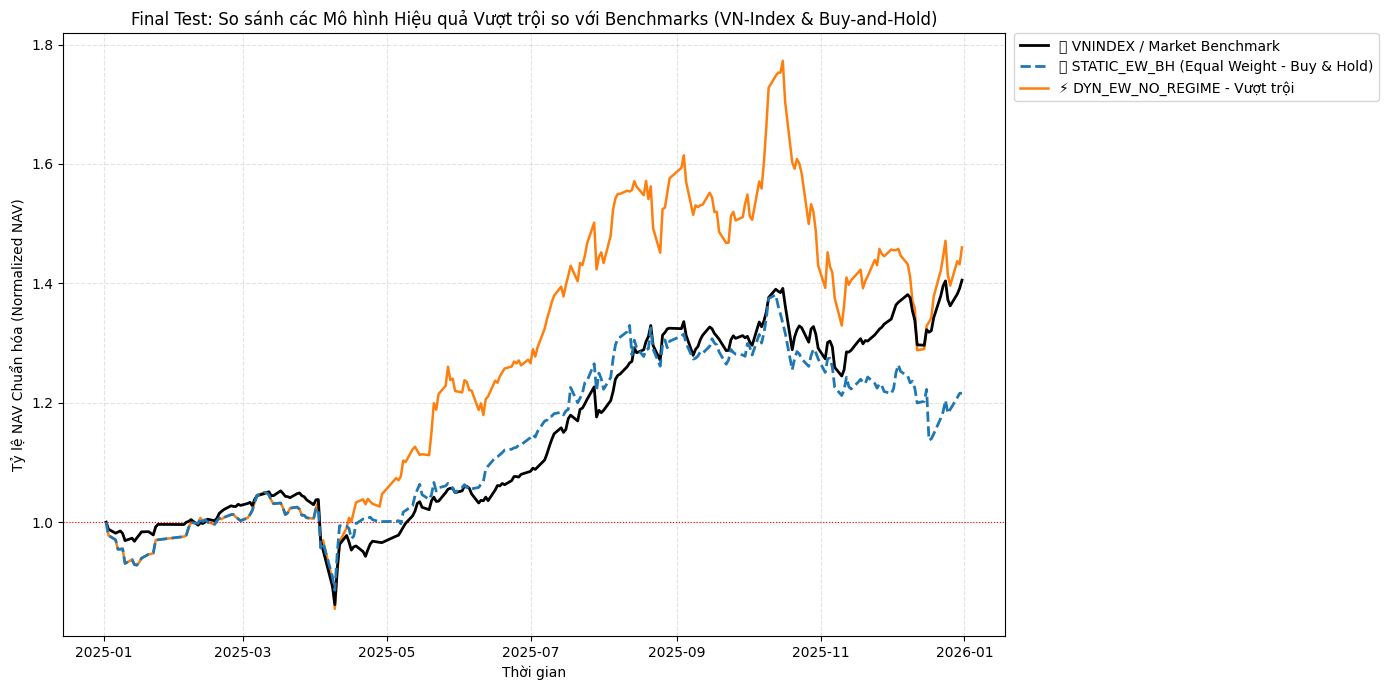

In [37]:
# ==========================================================
# 16. BIỂU ĐỒ NAV - CHỈ TRÌNH BÀY CÁC MÔ HÌNH HIỆU QUẢ HƠN BENCHMARKS
# ==========================================================
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

# Lấy NAV cuối kỳ của VNINDEX và STATIC_EW_BH để làm mốc so sánh
benchmark_key = "VNINDEX_or_MarketBenchmark"
buyhold_key = "STATIC_EW_BH"

nav_bench = pd.Series(test_curves[benchmark_key]).dropna() if benchmark_key in test_curves else pd.Series()
nav_bh = pd.Series(test_curves[buyhold_key]).dropna() if buyhold_key in test_curves else pd.Series()

final_bench = nav_bench.iloc[-1] / nav_bench.iloc[0] if len(nav_bench) else 0.0
final_bh = nav_bh.iloc[-1] / nav_bh.iloc[0] if len(nav_bh) else 0.0
max_benchmark_performance = max(final_bench, final_bh)

# Vẽ trước 2 đường Benchmarks chính để làm mốc đối chiếu
if len(nav_bench):
    plt.plot(nav_bench.index, nav_bench/nav_bench.iloc[0], label="📊 VNINDEX / Market Benchmark", linewidth=2.0, color="black", zorder=8)
if len(nav_bh):
    plt.plot(nav_bh.index, nav_bh/nav_bh.iloc[0], label="📌 STATIC_EW_BH (Equal Weight - Buy & Hold)", linewidth=2.0, linestyle="--", color="#1f77b4", zorder=9)

# Duyệt qua các mô hình khác và chỉ vẽ nếu hiệu quả vượt trội cả 2 benchmarks
for nm in test_curves.keys():
    if nm in [benchmark_key, buyhold_key]:
        continue

    nav = pd.Series(test_curves[nm]).dropna()
    if len(nav) == 0:
        continue

    final_perf = nav.iloc[-1] / nav.iloc[0]

    # Kiểm tra điều kiện hiệu quả vượt trội
    if final_perf > max_benchmark_performance:
        if nm == "LOCKED_CHAMPION":
            plt.plot(nav.index, nav/nav.iloc[0], label="🏆 LOCKED_CHAMPION (DYN_EW_REGIME) - Vượt trội", linewidth=2.5, color="#2ca02c", zorder=10)
        elif nm == "DYN_EW_NO_REGIME":
            plt.plot(nav.index, nav/nav.iloc[0], label="⚡ DYN_EW_NO_REGIME - Vượt trội", linewidth=1.8, color="#ff7f0e")
        else:
            clean_name = nm.replace("DIAG_", "")
            plt.plot(nav.index, nav/nav.iloc[0], label=f"✨ {clean_name} - Vượt trội", linewidth=1.5)

plt.axhline(1.0, color="red", linewidth=0.8, linestyle=":")
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0.)
plt.title("Final Test: So sánh các Mô hình Hiệu quả Vượt trội so với Benchmarks (VN-Index & Buy-and-Hold)")
plt.xlabel("Thời gian")
plt.ylabel("Tỷ lệ NAV Chuẩn hóa (Normalized NAV)")
plt.tight_layout()
plt.show()

## PHẦN 17 — Leakage Audit và xuất kết quả

Bảng `LeakageAudit` là phần nên trình bày trong bài để chứng minh mô hình không dùng dữ liệu tương lai.

Các sheet Excel gồm:

- DataQuality
- TimeSplit
- CoreTAThresholds
- ValSelectionHistory
- ValidationModels
- TestSelectionHistory
- FinalTest
- LeakageAudit


In [38]:
# 17A. Leakage Audit
leakage = pd.DataFrame([
    ["TA BUY/EXIT", core_end, False, "Chỉ Core Train"],
    ["Model family", val_end, False, "Chọn trên Validation bằng nested selection"],
    ["Quarterly Top N in Test", "t-1", False, "Mỗi kỳ chọn lại bằng dữ liệu <= phiên trước"],
    ["Monthly portfolio weights in Test", "t-1", False, "MPT/MinVar/HRP chỉ dùng prices <= phiên trước"],
    ["FA snapshot", "t-1", False, "Chỉ FA có effective_date <= as-of" if fa is not None else "Không có FA -> TA-only"],
    ["Market regime", "t-1 close", False, "Close(t-1) -> Open(t)"],
    ["Final Test metrics", test_end, True, "Chỉ đánh giá; không retune"],
], columns=["Stage","MaxInformationDate","UsesFinalTestForTuning","Rule"])

display(leakage)


,Stage,MaxInformationDate,UsesFinalTestForTuning,Rule
0,TA BUY/EXIT,2023-12-29 00:00:00,False,Chỉ Core Train
1,Model family,2024-12-31 00:00:00,False,Chọn trên Validation bằng nested selection
2,Quarterly Top N in Test,t-1,False,Mỗi kỳ chọn lại bằng dữ liệu <= phiên trước
3,Monthly portfolio weights in Test,t-1,False,MPT/MinVar/HRP chỉ dùng prices <= phiên trước
4,FA snapshot,t-1,False,Không có FA -> TA-only
5,Market regime,t-1 close,False,Close(t-1) -> Open(t)
6,Final Test metrics,2025-12-31 00:00:00,True,Chỉ đánh giá; không retune


In [39]:
# 17B. Xuất CSV + Excel
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

quality.to_csv(OUTPUT_DIR/"01_data_quality.csv", index=False, encoding="utf-8-sig")
split_table.to_csv(OUTPUT_DIR/"02_time_split.csv", index=False, encoding="utf-8-sig")
threshold_trials.to_csv(OUTPUT_DIR/"03_core_threshold_trials.csv", index=False, encoding="utf-8-sig")
val_selection.to_csv(OUTPUT_DIR/"04_validation_selection_history.csv", index=False, encoding="utf-8-sig")
val_results.reset_index().to_csv(OUTPUT_DIR/"05_validation_models.csv", index=False, encoding="utf-8-sig")
test_selection.to_csv(OUTPUT_DIR/"06_test_selection_history.csv", index=False, encoding="utf-8-sig")
test_results.reset_index().to_csv(OUTPUT_DIR/"07_final_test_results.csv", index=False, encoding="utf-8-sig")
leakage.to_csv(OUTPUT_DIR/"08_leakage_audit.csv", index=False, encoding="utf-8-sig")

excel_path = OUTPUT_DIR/"HOSE_V4_GENERIC_RESULTS.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    quality.to_excel(writer, sheet_name="DataQuality", index=False)
    split_table.to_excel(writer, sheet_name="TimeSplit", index=False)
    threshold_trials.to_excel(writer, sheet_name="CoreTAThresholds", index=False)
    val_selection.to_excel(writer, sheet_name="ValSelectionHistory", index=False)
    val_results.reset_index().to_excel(writer, sheet_name="ValidationModels", index=False)
    test_selection.to_excel(writer, sheet_name="TestSelectionHistory", index=False)
    test_results.reset_index().to_excel(writer, sheet_name="FinalTest", index=False)
    leakage.to_excel(writer, sheet_name="LeakageAudit", index=False)

print("Đã xuất kết quả vào:", excel_path)


Đã xuất kết quả vào: hose_v4_outputs/HOSE_V4_GENERIC_RESULTS.xlsx


# Gợi ý trình bày V4

Khi thuyết trình, có thể đi theo 6 ý chính:

1. **Bài toán:** từ universe ban đầu tìm danh mục cổ phiếu tốt rồi tối ưu allocation.
2. **No-leak design:** Core Train → Validation → Final Test.
3. **Stock selection:** TA/FA + risk gate + diversification.
4. **Cải tiến V4:** Nested Walk-Forward tái chọn Top N theo quý bằng dữ liệu `t−1`.
5. **Portfolio allocation:** EW, MPT-LW, MinVar-LW, HRP, Blend; weights cập nhật theo tháng.
6. **Risk management:** Market Regime + Cash, sau đó so sánh Locked Champion với Static EW Buy&Hold và VN-Index.

### Một câu giải thích ngắn về nested walk-forward

> “Tại mỗi kỳ tái cân bằng, mô hình giả định mình đang đứng đúng ở thời điểm đó. Nó chỉ được nhìn dữ liệu đã xuất hiện trước ngày giao dịch, sau đó chọn lại cổ phiếu và trọng số cho giai đoạn tiếp theo. Vì vậy thông tin của các phiên tương lai không tham gia vào quyết định hiện tại.”

### Lưu ý quan trọng

Không có thiết kế nào bảo đảm chắc chắn sẽ luôn vượt VN-Index. Mục tiêu của V4 là tăng tính thích nghi **mà không đánh đổi tính trung thực của OOS backtest**.
